In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'alzheimer_project.zip':
            print("FOUND:")
            print(os.path.join(root, file))

FOUND:
/content/drive/MyDrive/Alzheimer_Project.zip


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    files = zip_ref.namelist()

print("Total items inside ZIP:", len(files))

print("\nFirst 50 items:")
for f in files[:50]:
    print(f)

Total items inside ZIP: 3135

First 50 items:
Alzheimer_Project/
Alzheimer_Project/Dataset/
Alzheimer_Project/Dataset/ADNI/
Alzheimer_Project/Dataset/ADNI/002_S_0295/
Alzheimer_Project/Dataset/ADNI/002_S_0295/MPR__GradWarp__B1_Correction__N3/
Alzheimer_Project/Dataset/ADNI/002_S_0295/MPR__GradWarp__B1_Correction__N3/2006-04-18_08_20_30.0/
Alzheimer_Project/Dataset/ADNI/002_S_0295/MPR__GradWarp__B1_Correction__N3/2006-04-18_08_20_30.0/I45107/
Alzheimer_Project/Dataset/ADNI/002_S_0295/MPR__GradWarp__B1_Correction__N3/2006-04-18_08_20_30.0/I45107/ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correction__N3_Br_20070319113435616_S13408_I45107.nii
Alzheimer_Project/Dataset/ADNI/002_S_0413/
Alzheimer_Project/Dataset/ADNI/002_S_0413/MPR__GradWarp__B1_Correction__N3/
Alzheimer_Project/Dataset/ADNI/002_S_0413/MPR__GradWarp__B1_Correction__N3/2006-05-02_12_31_52.0/
Alzheimer_Project/Dataset/ADNI/002_S_0413/MPR__GradWarp__B1_Correction__N3/2006-05-02_12_31_52.0/I45116/
Alzheimer_Project/Dataset/ADNI/002_S_

In [ ]:
from collections import Counter
import os

extensions = Counter()

for f in files:
    if not f.endswith('/'):
        ext = os.path.splitext(f)[1].lower()
        extensions[ext] += 1

print("File extensions:\n")

for ext, count in extensions.items():
    print(f"{ext or '[no extension]'} : {count}")

File extensions:

.nii : 630
.csv : 6
.txt : 1
.png : 9


In [ ]:
print("Top-level folders/files:\n")

top_level = set()

for f in files:
    parts = f.split('/')
    top_level.add(parts[0])

for item in sorted(top_level):
    print(item)

Top-level folders/files:

Alzheimer_Project


In [ ]:
# ============================================
# 1. List all CSV files inside Alzheimer_Project.zip
# ============================================

import zipfile

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    csv_files = [f for f in zip_ref.namelist() if f.lower().endswith('.csv')]

print("CSV files inside ZIP:\n")

for i, f in enumerate(csv_files, 1):
    print(f"{i}. {f}")

CSV files inside ZIP:

1. Alzheimer_Project/Metadata/ADNI_labels.csv
2. Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv
3. Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_class_summary.csv
4. Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_complete_inspection.csv
5. Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_quality_flags.csv
6. Alzheimer_Project/Results/MRI_Inspection/subjects_with_multiple_MRIs.csv


In [ ]:
# ============================================
# 2. Inspect all CSV files
# ============================================

import pandas as pd

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    for csv_file in csv_files:

        print("\n" + "="*80)
        print("FILE:", csv_file)

        with zip_ref.open(csv_file) as f:
            temp_df = pd.read_csv(f)

        print("Shape:", temp_df.shape)
        print("Columns:")
        print(list(temp_df.columns))

        print("\nFirst 2 rows:")
        display(temp_df.head(2))


FILE: Alzheimer_Project/Metadata/ADNI_labels.csv
Shape: (630, 12)
Columns:
['Image Data ID', 'Subject', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'Downloaded']

First 2 rows:


,Image Data ID,Subject,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded
0,I63896,941_S_1363,MCI,F,70,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/12/2007,NiFTI,NaN
1,I97326,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,NaN



FILE: Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv
Shape: (630, 14)
Columns:
['Subject', 'Image_Data_ID', 'MRI_File_Name', 'MRI_Path', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'Downloaded']

First 2 rows:


,Subject,Image_Data_ID,MRI_File_Name,MRI_Path,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded
0,002_S_0295,I45107,ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0295\M...,CN,M,85,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-04-18,NiFTI,NaN
1,002_S_0413,I45116,ADNI_002_S_0413_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0413\M...,CN,F,76,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-05-02,NiFTI,NaN



FILE: Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_class_summary.csv
Shape: (3, 7)
Columns:
['Group', 'MRI_Count', 'Unique_Subjects', 'Mean_Age', 'Mean_Intensity', 'Mean_STD', 'Mean_Zero_Percent']

First 2 rows:


,Group,MRI_Count,Unique_Subjects,Mean_Age,Mean_Intensity,Mean_STD,Mean_Zero_Percent
0,AD,149,145,75.919,178.984,270.836,44.035
1,CN,174,169,76.333,176.585,263.703,43.413


... (2 outputs left out)


FILE: Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_quality_flags.csv
Shape: (0, 37)
Columns:
['Subject', 'Image_Data_ID', 'Group', 'Sex', 'Age', 'MRI_File_Name', 'MRI_Path', 'File_Exists', 'File_Size_MB', 'Load_Status', 'Dimensions', 'Dim_X', 'Dim_Y', 'Dim_Z', 'Num_Dimensions', 'Voxel_X_mm', 'Voxel_Y_mm', 'Voxel_Z_mm', 'Data_Type', 'Orientation', 'Intensity_Min', 'Intensity_Max', 'Intensity_Mean', 'Intensity_STD', 'P01', 'P05', 'P25', 'P50', 'P75', 'P95', 'P99', 'Zero_Voxel_Percent', 'NaN_Count', 'Inf_Count', 'Affine', 'Error', 'Potential_Issue']

First 2 rows:


,Subject,Image_Data_ID,Group,Sex,Age,MRI_File_Name,MRI_Path,File_Exists,File_Size_MB,Load_Status,...,P50,P75,P95,P99,Zero_Voxel_Percent,NaN_Count,Inf_Count,Affine,Error,Potential_Issue



FILE: Alzheimer_Project/Results/MRI_Inspection/subjects_with_multiple_MRIs.csv
Shape: (19, 2)
Columns:
['Subject', 'MRI_Count']

First 2 rows:


,Subject,MRI_Count
0,003_S_1122,2
1,005_S_0572,2


In [ ]:
# ============================================
# 3. Count MRI files and extract Image IDs
# ============================================

import re

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    nii_files = [
        f for f in zip_ref.namelist()
        if f.lower().endswith('.nii')
    ]

print("Total NIfTI files:", len(nii_files))

# Extract Image Data IDs such as I45107 from filenames
image_ids = []

for f in nii_files:
    filename = f.split('/')[-1]

    match = re.search(r'_I(\d+)\.nii$', filename)

    if match:
        image_ids.append("I" + match.group(1))

print("Image IDs extracted:", len(image_ids))
print("Unique Image IDs:", len(set(image_ids)))

print("\nFirst 20 Image IDs:")
print(image_ids[:20])

Total NIfTI files: 630
Image IDs extracted: 630
Unique Image IDs: 630

First 20 Image IDs:
['I45107', 'I45116', 'I40673', 'I40682', 'I40707', 'I40716', 'I40730', 'I40979', 'I40739', 'I40753', 'I40816', 'I40830', 'I40844', 'I62376', 'I64036', 'I60055', 'I52780', 'I62588', 'I53385', 'I52771']


In [ ]:
# ============================================================
# STEP 4: COMPLETE DATASET VALIDATION
# ============================================================

import zipfile
import pandas as pd
import re
import os

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    # --------------------------------------------------------
    # 1. Read the main label CSV
    # --------------------------------------------------------
    with z.open("Alzheimer_Project/Metadata/ADNI_labels.csv") as f:
        labels = pd.read_csv(f)

    # --------------------------------------------------------
    # 2. Read MRI inventory
    # --------------------------------------------------------
    with z.open("Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv") as f:
        inventory = pd.read_csv(f)

    # --------------------------------------------------------
    # 3. Read complete MRI inspection
    # --------------------------------------------------------
    with z.open(
        "Alzheimer_Project/Results/MRI_Inspection/ADNI_MRI_complete_inspection.csv"
    ) as f:
        inspection = pd.read_csv(f)

    # --------------------------------------------------------
    # 4. Get all NIfTI files
    # --------------------------------------------------------
    nii_files = [
        f for f in z.namelist()
        if f.lower().endswith(".nii")
    ]

# ============================================================
# BASIC COUNTS
# ============================================================

print("=" * 60)
print("DATASET VALIDATION")
print("=" * 60)

print("\nLabel records       :", len(labels))
print("Inventory records   :", len(inventory))
print("Inspection records  :", len(inspection))
print("NIfTI MRI files     :", len(nii_files))

# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLASS DISTRIBUTION")
print("=" * 60)

print(labels["Group"].value_counts())

print("\nPercentage:")
print(
    (labels["Group"].value_counts(normalize=True) * 100)
    .round(2)
)

# ============================================================
# UNIQUE SUBJECTS
# ============================================================

print("\n" + "=" * 60)
print("SUBJECT ANALYSIS")
print("=" * 60)

print("Total unique subjects:", labels["Subject"].nunique())

print("\nUnique subjects per class:")
print(
    labels.groupby("Group")["Subject"]
    .nunique()
    .sort_values(ascending=False)
)

# ============================================================
# DUPLICATE IMAGE IDs
# ============================================================

print("\n" + "=" * 60)
print("DUPLICATE CHECK")
print("=" * 60)

print("Duplicate Image Data IDs:",
      labels["Image Data ID"].duplicated().sum())

print("Duplicate MRI filenames:",
      inventory["MRI_File_Name"].duplicated().sum())

# ============================================================
# MULTIPLE MRI RECORDS PER SUBJECT
# ============================================================

subject_counts = labels.groupby("Subject").size()

print("\nSubjects with multiple MRI records:",
      (subject_counts > 1).sum())

print("Maximum MRI records for one subject:",
      subject_counts.max())

# ============================================================
# INSPECTION STATUS
# ============================================================

print("\n" + "=" * 60)
print("MRI QUALITY / LOADING CHECK")
print("=" * 60)

print("\nLoad status:")
print(inspection["Load_Status"].value_counts(dropna=False))

print("\nFile exists:")
print(inspection["File_Exists"].value_counts(dropna=False))

print("\nNaN values:")
print(inspection["NaN_Count"].value_counts().head())

print("\nInf values:")
print(inspection["Inf_Count"].value_counts().head())

# ============================================================
# MRI DIMENSIONS
# ============================================================

print("\n" + "=" * 60)
print("MRI DIMENSIONS")
print("=" * 60)

print(inspection["Dimensions"].value_counts().head(20))

print("\nNumber of unique dimensions:",
      inspection["Dimensions"].nunique())

# ============================================================
# IMAGE ID MATCHING
# ============================================================

print("\n" + "=" * 60)
print("MRI ↔ METADATA MATCHING")
print("=" * 60)

nii_image_ids = []

for path in nii_files:

    filename = os.path.basename(path)

    match = re.search(r"_I(\d+)\.nii$", filename)

    if match:
        nii_image_ids.append("I" + match.group(1))

nii_image_ids = set(nii_image_ids)
csv_image_ids = set(labels["Image Data ID"].astype(str))

print("Image IDs in CSV :", len(csv_image_ids))
print("Image IDs in NII :", len(nii_image_ids))

print("CSV IDs missing from NII:",
      len(csv_image_ids - nii_image_ids))

print("NII IDs missing from CSV:",
      len(nii_image_ids - csv_image_ids))

print("\n" + "=" * 60)
print("VALIDATION COMPLETE")
print("=" * 60)

DATASET VALIDATION

Label records       : 630
Inventory records   : 630
Inspection records  : 630
NIfTI MRI files     : 630

CLASS DISTRIBUTION
Group
MCI    307
CN     174
AD     149
Name: count, dtype: int64

Percentage:
Group
MCI    48.73
CN     27.62
AD     23.65
Name: proportion, dtype: float64

SUBJECT ANALYSIS
Total unique subjects: 610

Unique subjects per class:
Group
MCI    296
CN     169
AD     145
Name: Subject, dtype: int64

DUPLICATE CHECK
Duplicate Image Data IDs: 0
Duplicate MRI filenames: 0

Subjects with multiple MRI records: 19
Maximum MRI records for one subject: 3

MRI QUALITY / LOADING CHECK

Load status:
Load_Status
OK    630
Name: count, dtype: int64

File exists:
File_Exists
True    630
Name: count, dtype: int64

NaN values:
NaN_Count
0    630
Name: count, dtype: int64

Inf values:
Inf_Count
0    630
Name: count, dtype: int64

MRI DIMENSIONS
Dimensions
(192, 192, 160)    341
(256, 256, 166)    287
(256, 256, 146)      1
(256, 256, 162)      1
Name: count, dtype:

In [ ]:
# ============================================================
# STEP 5: CREATE CLEAN MASTER METADATA
# ============================================================

import zipfile
import pandas as pd
import os

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    # Load labels
    with z.open("Alzheimer_Project/Metadata/ADNI_labels.csv") as f:
        labels = pd.read_csv(f)

    # Load MRI inventory
    with z.open("Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv") as f:
        inventory = pd.read_csv(f)

# ------------------------------------------------------------
# Select required columns
# ------------------------------------------------------------

metadata = labels[
    [
        "Image Data ID",
        "Subject",
        "Group",
        "Sex",
        "Age",
        "Visit",
        "Modality",
        "Description",
        "Type",
        "Acq Date",
        "Format"
    ]
].copy()

# ------------------------------------------------------------
# Add MRI filename/path from inventory
# ------------------------------------------------------------

inventory_small = inventory[
    [
        "Image_Data_ID",
        "MRI_File_Name",
        "MRI_Path"
    ]
].copy()

inventory_small = inventory_small.rename(
    columns={"Image_Data_ID": "Image Data ID"}
)

metadata = metadata.merge(
    inventory_small,
    on="Image Data ID",
    how="left"
)

# ------------------------------------------------------------
# Display result
# ------------------------------------------------------------

print("Metadata shape:", metadata.shape)

print("\nColumns:")
print(metadata.columns.tolist())

print("\nFirst 5 records:")
display(metadata.head())

print("\nMissing values:")
print(metadata.isnull().sum())

Metadata shape: (630, 13)

Columns:
['Image Data ID', 'Subject', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'MRI_File_Name', 'MRI_Path']

First 5 records:


,Image Data ID,Subject,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,MRI_File_Name,MRI_Path
0,I63896,941_S_1363,MCI,F,70,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/12/2007,NiFTI,ADNI_941_S_1363_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1363\M...
1,I97326,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,ADNI_941_S_1311_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1311\M...
2,I97331,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,ADNI_941_S_1311_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1311\M...
3,I63887,941_S_1295,MCI,M,77,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2/09/2007,NiFTI,ADNI_941_S_1295_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1295\M...
4,I63878,941_S_1203,CN,M,83,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,1/29/2007,NiFTI,ADNI_941_S_1203_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1203\M...



Missing values:
Image Data ID    0
Subject          0
Group            0
Sex              0
Age              0
Visit            0
Modality         0
Description      0
Type             0
Acq Date         0
Format           0
MRI_File_Name    0
MRI_Path         0
dtype: int64


In [ ]:
print("Class distribution:")
print(metadata["Group"].value_counts())

print("\nSubject distribution:")
print(
    metadata.groupby("Group")["Subject"]
    .nunique()
)

Class distribution:
Group
MCI    307
CN     174
AD     149
Name: count, dtype: int64

Subject distribution:
Group
AD     145
CN     169
MCI    296
Name: Subject, dtype: int64


In [ ]:
multiple_subjects = (
    metadata.groupby("Subject")
    .size()
    .reset_index(name="MRI_Count")
)

multiple_subjects = multiple_subjects[
    multiple_subjects["MRI_Count"] > 1
]

print("Subjects with multiple MRI scans:")
display(multiple_subjects)

print("\nNumber of such subjects:",
      len(multiple_subjects))

Subjects with multiple MRI scans:


,Subject,MRI_Count
24,003_S_1122,2
33,005_S_0572,2
42,006_S_0498,2
44,006_S_0547,2
45,006_S_0653,2
98,013_S_1275,2
114,016_S_0538,2
129,020_S_0883,2
148,022_S_1366,2
267,035_S_0555,2



Number of such subjects: 19


In [ ]:
# ============================================================
# RECREATE METADATA
# ============================================================

import zipfile
import pandas as pd

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

with zipfile.ZipFile(zip_path, 'r') as z:

    # Load labels
    with z.open("Alzheimer_Project/Metadata/ADNI_labels.csv") as f:
        labels = pd.read_csv(f)

    # Load MRI inventory
    with z.open("Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv") as f:
        inventory = pd.read_csv(f)

# Select required columns
metadata = labels[
    [
        "Image Data ID",
        "Subject",
        "Group",
        "Sex",
        "Age",
        "Visit",
        "Modality",
        "Description",
        "Type",
        "Acq Date",
        "Format"
    ]
].copy()

# Select MRI file information
inventory_small = inventory[
    [
        "Image_Data_ID",
        "MRI_File_Name",
        "MRI_Path"
    ]
].copy()

# Rename so we can merge
inventory_small = inventory_small.rename(
    columns={"Image_Data_ID": "Image Data ID"}
)

# Merge
metadata = metadata.merge(
    inventory_small,
    on="Image Data ID",
    how="left"
)

print("Metadata created successfully!")
print("Shape:", metadata.shape)

display(metadata.head())

Metadata created successfully!
Shape: (630, 13)


,Image Data ID,Subject,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,MRI_File_Name,MRI_Path
0,I63896,941_S_1363,MCI,F,70,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/12/2007,NiFTI,ADNI_941_S_1363_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1363\M...
1,I97326,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,ADNI_941_S_1311_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1311\M...
2,I97331,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,ADNI_941_S_1311_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1311\M...
3,I63887,941_S_1295,MCI,M,77,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2/09/2007,NiFTI,ADNI_941_S_1295_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1295\M...
4,I63878,941_S_1203,CN,M,83,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,1/29/2007,NiFTI,ADNI_941_S_1203_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\941_S_1203\M...


In [ ]:
# ============================================================
# STEP 6: SUBJECT-WISE STRATIFIED TRAIN / VAL / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd

# ------------------------------------------------------------
# 1. Create one row per subject
# ------------------------------------------------------------

subject_df = (
    metadata.groupby("Subject")
    .agg(
        Group=("Group", "first")
    )
    .reset_index()
)

print("Total unique subjects:", len(subject_df))

print("\nSubject distribution:")
print(subject_df["Group"].value_counts())

# ------------------------------------------------------------
# 2. Split subjects into TRAIN (70%) and TEMP (30%)
# ------------------------------------------------------------

train_subjects, temp_subjects = train_test_split(
    subject_df,
    test_size=0.30,
    stratify=subject_df["Group"],
    random_state=42
)

# ------------------------------------------------------------
# 3. Split TEMP into VALIDATION (15%) and TEST (15%)
# ------------------------------------------------------------

val_subjects, test_subjects = train_test_split(
    temp_subjects,
    test_size=0.50,
    stratify=temp_subjects["Group"],
    random_state=42
)

# ------------------------------------------------------------
# 4. Display subject counts
# ------------------------------------------------------------

print("\n" + "="*60)
print("SUBJECT SPLIT")
print("="*60)

print("Training subjects   :", len(train_subjects))
print("Validation subjects :", len(val_subjects))
print("Test subjects       :", len(test_subjects))

print("\nTotal:",
      len(train_subjects) +
      len(val_subjects) +
      len(test_subjects))

# ------------------------------------------------------------
# 5. Class distribution
# ------------------------------------------------------------

print("\n" + "="*60)
print("TRAIN CLASS DISTRIBUTION")
print("="*60)

print(train_subjects["Group"].value_counts())

print("\n" + "="*60)
print("VALIDATION CLASS DISTRIBUTION")
print("="*60)

print(val_subjects["Group"].value_counts())

print("\n" + "="*60)
print("TEST CLASS DISTRIBUTION")
print("="*60)

print(test_subjects["Group"].value_counts())

Total unique subjects: 610

Subject distribution:
Group
MCI    296
CN     169
AD     145
Name: count, dtype: int64

SUBJECT SPLIT
Training subjects   : 427
Validation subjects : 91
Test subjects       : 92

Total: 610

TRAIN CLASS DISTRIBUTION
Group
MCI    207
CN     118
AD     102
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION
Group
MCI    44
CN     25
AD     22
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
Group
MCI    45
CN     26
AD     21
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 7: ASSIGN MRI RECORDS TO TRAIN / VALIDATION / TEST
# ============================================================

train_ids = set(train_subjects["Subject"])
val_ids = set(val_subjects["Subject"])
test_ids = set(test_subjects["Subject"])

metadata["Split"] = metadata["Subject"].apply(
    lambda x:
        "train" if x in train_ids
        else "validation" if x in val_ids
        else "test" if x in test_ids
        else "UNKNOWN"
)

print("MRI records by split:")
print(metadata["Split"].value_counts())

print("\nMRI records by split and class:")
print(
    pd.crosstab(
        metadata["Split"],
        metadata["Group"]
    )
)

MRI records by split:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

MRI records by split and class:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47


In [ ]:
# ============================================================
# STEP 8: SUBJECT LEAKAGE CHECK
# ============================================================

train_set = set(
    metadata.loc[metadata["Split"] == "train", "Subject"]
)

val_set = set(
    metadata.loc[metadata["Split"] == "validation", "Subject"]
)

test_set = set(
    metadata.loc[metadata["Split"] == "test", "Subject"]
)

print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test      :", len(train_set & test_set))
print("Validation ∩ Test :", len(val_set & test_set))

print("\nUnknown records:",
      (metadata["Split"] == "UNKNOWN").sum())

Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0

Unknown records: 0


In [ ]:
# ============================================================
# STEP 9: SAVE FINAL SPLIT METADATA
# ============================================================

output_path = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata.to_csv(output_path, index=False)

print("Saved successfully!")
print(output_path)
print("Shape:", metadata.shape)

Saved successfully!
/content/drive/MyDrive/metadata_subjectwise_split.csv
Shape: (630, 14)


In [ ]:
print(metadata["Split"].value_counts())

print("\nSplit × Group:")
print(pd.crosstab(metadata["Split"], metadata["Group"]))

Split
train         443
validation     95
test           92
Name: count, dtype: int64

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47


In [ ]:
# ============================================================
# STEP 10: INSPECT ONE MRI VOLUME
# ============================================================

import zipfile
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

# Pick the first MRI from our metadata
sample_row = metadata.iloc[0]

print("Subject      :", sample_row["Subject"])
print("Group        :", sample_row["Group"])
print("Image ID     :", sample_row["Image Data ID"])
print("MRI filename :", sample_row["MRI_File_Name"])

# Find the MRI inside ZIP
with zipfile.ZipFile(zip_path, 'r') as z:

    nii_path = [
        f for f in z.namelist()
        if f.endswith(".nii")
        and sample_row["Image Data ID"] in os.path.basename(f)
    ][0]

    print("\nZIP path:")
    print(nii_path)

    # Extract temporarily
    temp_path = "/content/sample_mri.nii"

    with z.open(nii_path) as source, open(temp_path, "wb") as target:
        target.write(source.read())

# Load MRI
img = nib.load(temp_path)

data = img.get_fdata()

print("\n" + "="*60)
print("MRI INFORMATION")
print("="*60)

print("Shape:", data.shape)
print("Voxel spacing:", img.header.get_zooms())
print("Data type:", data.dtype)
print("Minimum intensity:", np.min(data))
print("Maximum intensity:", np.max(data))
print("Mean intensity:", np.mean(data))
print("STD:", np.std(data))

Subject      : 941_S_1363
Group        : MCI
Image ID     : I63896
MRI filename : ADNI_941_S_1363_MR_MPR__GradWarp__B1_Correction__N3_Br_20070801202834358_S28008_I63896.nii

ZIP path:
Alzheimer_Project/Dataset/ADNI/941_S_1363/MPR__GradWarp__B1_Correction__N3/2007-03-12_12_46_38.0/I63896/ADNI_941_S_1363_MR_MPR__GradWarp__B1_Correction__N3_Br_20070801202834358_S28008_I63896.nii

MRI INFORMATION
Shape: (192, 192, 160)
Voxel spacing: (np.float32(1.25), np.float32(1.25), np.float32(1.2))
Data type: float64
Minimum intensity: 0.0
Maximum intensity: 1863.4332275390625
Mean intensity: 179.07029348008425
STD: 283.5617027713105


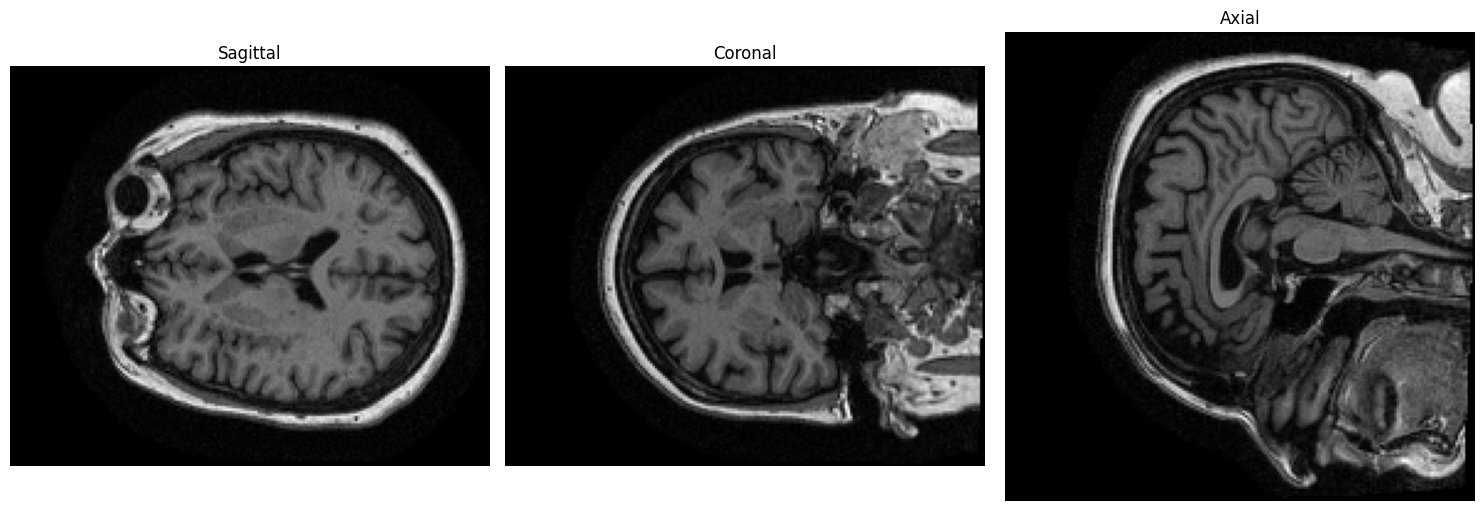

In [ ]:
# ============================================================
# VISUALIZE MIDDLE SLICES
# ============================================================

mid_x = data.shape[0] // 2
mid_y = data.shape[1] // 2
mid_z = data.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(
    np.rot90(data[mid_x, :, :]),
    cmap="gray"
)
axes[0].set_title("Sagittal")
axes[0].axis("off")

axes[1].imshow(
    np.rot90(data[:, mid_y, :]),
    cmap="gray"
)
axes[1].set_title("Coronal")
axes[1].axis("off")

axes[2].imshow(
    np.rot90(data[:, :, mid_z]),
    cmap="gray"
)
axes[2].set_title("Axial")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip -q install nibabel nilearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from nilearn.image import resample_img

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Alzheimer_Project.zip"

sample_row = metadata.iloc[0]

with zipfile.ZipFile(zip_path, 'r') as z:

    nii_path = [
        f for f in z.namelist()
        if f.endswith(".nii")
        and sample_row["Image Data ID"] in os.path.basename(f)
    ][0]

    temp_path = "/content/sample_mri.nii"

    with z.open(nii_path) as source, open(temp_path, "wb") as target:
        target.write(source.read())

img = nib.load(temp_path)

print("Original shape:", img.shape)
print("Original voxel spacing:", img.header.get_zooms())

Original shape: (192, 192, 160)
Original voxel spacing: (np.float32(1.25), np.float32(1.25), np.float32(1.2))


In [ ]:
from nibabel.orientations import aff2axcodes

print("Original orientation:",
      aff2axcodes(img.affine))

img_ras = nib.as_closest_canonical(img)

print("Standardized orientation:",
      aff2axcodes(img_ras.affine))

print("Shape after orientation:",
      img_ras.shape)

Original orientation: ('I', 'P', 'L')
Standardized orientation: ('R', 'A', 'S')
Shape after orientation: (160, 192, 192)


In [ ]:
target_voxel_size = (1.5, 1.5, 1.5)

current_affine = img_ras.affine.copy()

new_affine = np.diag([
    target_voxel_size[0],
    target_voxel_size[1],
    target_voxel_size[2],
    1
])

# Preserve the translation/origin
new_affine[:3, 3] = current_affine[:3, 3]

# Calculate new dimensions
old_shape = np.array(img_ras.shape)
old_zooms = np.array(img_ras.header.get_zooms()[:3])

new_shape = np.round(
    old_shape * old_zooms / np.array(target_voxel_size)
).astype(int)

print("Original shape :", img_ras.shape)
print("Original zooms :", old_zooms)
print("New shape      :", tuple(new_shape))
print("Target spacing :", target_voxel_size)

Original shape : (160, 192, 192)
Original zooms : [1.2  1.25 1.25]
New shape      : (np.int64(128), np.int64(160), np.int64(160))
Target spacing : (1.5, 1.5, 1.5)


In [ ]:
img_resampled = resample_img(
    img_ras,
    target_affine=new_affine,
    target_shape=tuple(new_shape),
    interpolation="continuous"
)

resampled_data = img_resampled.get_fdata()

print("Resampled shape:", resampled_data.shape)
print("Resampled zooms:", img_resampled.header.get_zooms())

Resampled shape: (128, 160, 160)
Resampled zooms: (np.float32(1.5), np.float32(1.5), np.float32(1.5))


In [ ]:
data = resampled_data.astype(np.float32)

brain_values = data[data > 0]

print("Before normalization:")
print("Min:", brain_values.min())
print("Max:", brain_values.max())
print("Mean:", brain_values.mean())
print("STD:", brain_values.std())

Before normalization:
Min: 1e-45
Max: 1631.9967
Mean: 230.31734
STD: 301.53265


In [ ]:
p1, p99 = np.percentile(brain_values, [1, 99])

data_clipped = np.clip(data, p1, p99)

mask = data_clipped > 0

mean = data_clipped[mask].mean()
std = data_clipped[mask].std()

data_normalized = np.zeros_like(data_clipped)

data_normalized[mask] = (
    data_clipped[mask] - mean
) / (std + 1e-8)

print("After normalization:")
print("Min:", data_normalized[mask].min())
print("Max:", data_normalized[mask].max())
print("Mean:", data_normalized[mask].mean())
print("STD:", data_normalized[mask].std())

After normalization:
Min: -0.6359850841515875
Max: 3.280469709541564
Mean: 3.1752378504279476e-16
STD: 0.9999999999643902


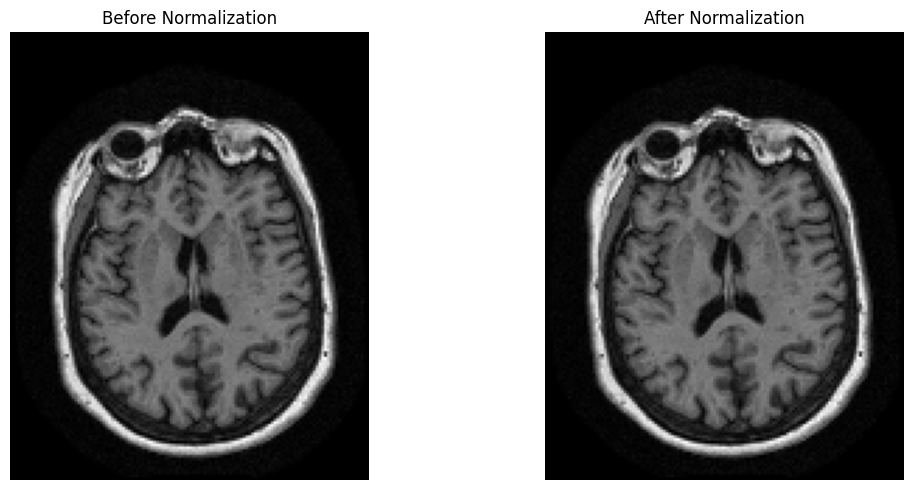

In [ ]:
mid_z = data.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    np.rot90(data[:, :, mid_z]),
    cmap="gray"
)
axes[0].set_title("Before Normalization")
axes[0].axis("off")

axes[1].imshow(
    np.rot90(data_normalized[:, :, mid_z]),
    cmap="gray"
)
axes[1].set_title("After Normalization")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip -q install mri-synthstrip

ERROR: Could not find a version that satisfies the requirement mri-synthstrip (from versions: none)
ERROR: No matching distribution found for mri-synthstrip


In [ ]:
!mri_synthstrip --help

/bin/bash: line 1: mri_synthstrip: command not found


In [ ]:
import numpy as np
from scipy import ndimage

# MRI data
data = resampled_data.astype(np.float32)

# Ignore extremely small background/interpolation values
threshold = 0.05 * np.max(data)

initial_mask = data > threshold

# Find connected components
labeled, num_features = ndimage.label(initial_mask)

print("Connected components:", num_features)

if num_features > 0:

    component_sizes = np.bincount(labeled.ravel())

    # Ignore background
    component_sizes[0] = 0

    largest_component = np.argmax(component_sizes)

    brain_mask = labeled == largest_component

else:
    brain_mask = initial_mask

# Fill holes
brain_mask = ndimage.binary_fill_holes(brain_mask)

# Morphological cleanup
brain_mask = ndimage.binary_opening(
    brain_mask,
    structure=np.ones((3, 3, 3))
)

brain_mask = ndimage.binary_closing(
    brain_mask,
    structure=np.ones((5, 5, 5))
)

# Apply mask
brain_data = np.where(brain_mask, data, 0)

print("Brain mask created.")
print("Brain voxels:", brain_mask.sum())
print(
    "Brain percentage:",
    round(100 * brain_mask.mean(), 2),
    "%"
)

Connected components: 4809
Brain mask created.
Brain voxels: 1216628
Brain percentage: 37.13 %


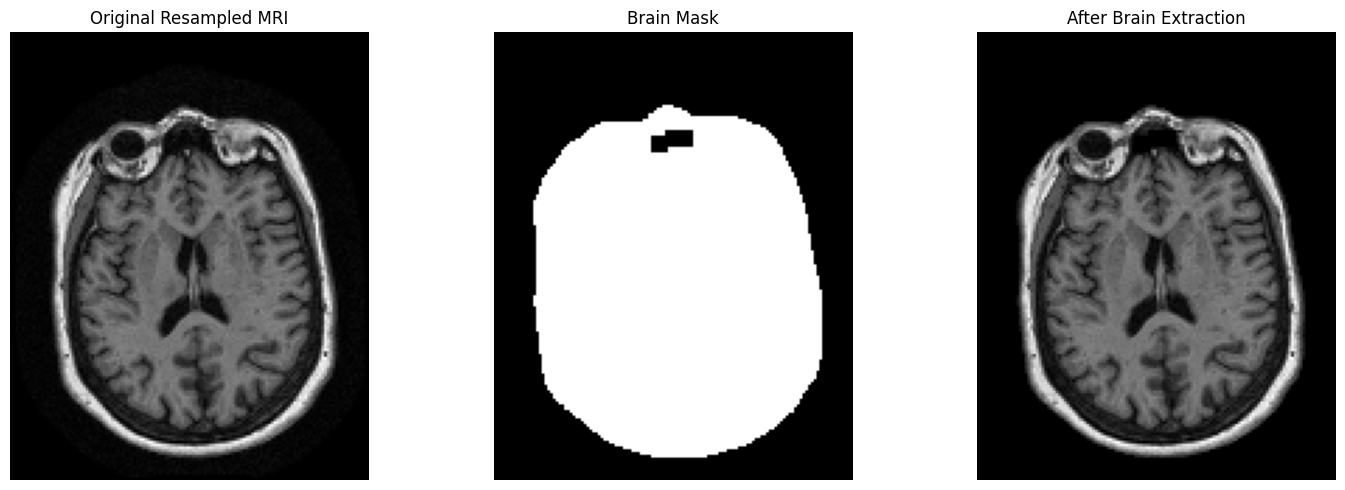

In [ ]:
import matplotlib.pyplot as plt

# Middle axial slice
z = data.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original
axes[0].imshow(
    np.rot90(data[:, :, z]),
    cmap="gray"
)
axes[0].set_title("Original Resampled MRI")

# Mask
axes[1].imshow(
    np.rot90(brain_mask[:, :, z]),
    cmap="gray"
)
axes[1].set_title("Brain Mask")

# Extracted brain
axes[2].imshow(
    np.rot90(brain_data[:, :, z]),
    cmap="gray"
)
axes[2].set_title("After Brain Extraction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 11A: DOWNLOAD OFFICIAL SYNTHSTRIP
# ============================================================

!wget -q \
https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/synthstrip-docker \
-O /content/synthstrip-docker

!chmod +x /content/synthstrip-docker

print("SynthStrip wrapper downloaded.")

SynthStrip wrapper downloaded.


In [ ]:
# ============================================================
# STEP 11B: DOWNLOAD SYNTHSTRIP MODEL WEIGHTS
# ============================================================

!wget -q \
https://surfer.nmr.mgh.harvard.edu/docs/synthstrip/requirements/synthstrip.1.pt \
-O /content/synthstrip.1.pt

import os

weight_path = "/content/synthstrip.1.pt"

print("Weights downloaded:", os.path.exists(weight_path))

if os.path.exists(weight_path):
    print("Weight file size:",
          round(os.path.getsize(weight_path) / (1024**2), 2),
          "MB")

Weights downloaded: True
Weight file size: 29.42 MB


In [ ]:
# ============================================================
# STEP 11C: DOWNLOAD SYNTHSTRIP PYTHON SCRIPT
# ============================================================

!wget -q \
https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/synthstrip \
-O /content/synthstrip.py

print("SynthStrip script downloaded.")

!head -20 /content/synthstrip.py

SynthStrip script downloaded.


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
# ============================================================
# STEP 11E-1: SAVE RESAMPLED MRI
# ============================================================

import nibabel as nib
import os

resampled_path = "/content/sample_resampled.nii.gz"

nib.save(img_resampled, resampled_path)

print("Saved:", resampled_path)
print("File exists:", os.path.exists(resampled_path))

if os.path.exists(resampled_path):
    print(
        "File size:",
        round(os.path.getsize(resampled_path) / (1024**2), 2),
        "MB"
    )

Saved: /content/sample_resampled.nii.gz
File exists: True
File size: 9.8 MB


In [ ]:
!python /content/synthstrip.py --help

In [ ]:
!rm -f /content/synthstrip.py

In [ ]:
!git clone -q --depth 1 https://github.com/freesurfer/freesurfer.git /content/freesurfer

In [ ]:
import os

synth_dir = "/content/freesurfer/mri_synthstrip"

print("SynthStrip directory exists:", os.path.exists(synth_dir))

if os.path.exists(synth_dir):
    print("\nFiles inside:")
    for f in os.listdir(synth_dir):
        print(f)

SynthStrip directory exists: True

Files inside:
Dockerfile.gpu
testdata.tar.gz
synthstrip.1.pt
synthstrip-singularity
CMakeLists.txt
synthstrip.nocsf.1.pt
readme.md
test.sh
synthstrip-docker
mri_synthstrip
Dockerfile.cpu


In [ ]:
# ============================================================
# STEP 11E: SET UP SYNTHSTRIP
# ============================================================

import os

synth_dir = "/content/freesurfer/mri_synthstrip"

# Copy the SynthStrip model to the location expected by the script
os.makedirs("/content/freesurfer/models", exist_ok=True)

!cp /content/freesurfer/mri_synthstrip/synthstrip.1.pt \
   /content/freesurfer/models/synthstrip.1.pt

# Tell SynthStrip where FreeSurfer is
os.environ["FREESURFER_HOME"] = "/content/freesurfer"

# Add SynthStrip directory to PATH
os.environ["PATH"] = synth_dir + ":" + os.environ["PATH"]

print("FREESURFER_HOME:", os.environ["FREESURFER_HOME"])

print("Model exists:",
      os.path.exists("/content/freesurfer/models/synthstrip.1.pt"))

print("SynthStrip exists:",
      os.path.exists("/content/freesurfer/mri_synthstrip/mri_synthstrip"))

cp: cannot stat '/content/freesurfer/mri_synthstrip/synthstrip.1.pt': No such file or directory
FREESURFER_HOME: /content/freesurfer
Model exists: False
SynthStrip exists: True


In [ ]:
import os

print("Searching for SynthStrip model...\n")

for root, dirs, files in os.walk("/content/freesurfer"):
    for file in files:
        if file == "synthstrip.1.pt":
            print("FOUND:")
            print(os.path.join(root, file))

Searching for SynthStrip model...

FOUND:
/content/freesurfer/mri_synthstrip/synthstrip.1.pt


In [ ]:
import os

synth_dir = "/content/freesurfer/mri_synthstrip"

# Make SynthStrip executable
!chmod +x /content/freesurfer/mri_synthstrip/mri_synthstrip

# Add SynthStrip to PATH
os.environ["PATH"] = synth_dir + ":" + os.environ["PATH"]

print("SynthStrip executable:",
      os.path.exists(f"{synth_dir}/mri_synthstrip"))

print("SynthStrip model:",
      os.path.exists(f"{synth_dir}/synthstrip.1.pt"))

SynthStrip executable: True
SynthStrip model: False


In [ ]:
import os

model_path = "/content/synthstrip.1.pt"

print("Exists:", os.path.isfile(model_path))

if os.path.isfile(model_path):
    print(
        "Size:",
        round(os.path.getsize(model_path) / (1024**2), 2),
        "MB"
    )

Exists: True
Size: 29.42 MB


In [ ]:
import os
import shutil

models_dir = "/content/freesurfer/models"
os.makedirs(models_dir, exist_ok=True)

shutil.copy2(
    "/content/synthstrip.1.pt",
    "/content/freesurfer/models/synthstrip.1.pt"
)

print("Model exists:",
      os.path.isfile("/content/freesurfer/models/synthstrip.1.pt"))

print(
    "Model size:",
    round(
        os.path.getsize("/content/freesurfer/models/synthstrip.1.pt")
        / (1024**2),
        2
    ),
    "MB"
)

Model exists: True
Model size: 29.42 MB


In [ ]:
import os

os.environ["FREESURFER_HOME"] = "/content/freesurfer"

os.environ["PATH"] = (
    "/content/freesurfer/mri_synthstrip:"
    + os.environ["PATH"]
)

print("FREESURFER_HOME:", os.environ["FREESURFER_HOME"])

FREESURFER_HOME: /content/freesurfer


In [ ]:
!chmod +x /content/freesurfer/mri_synthstrip/mri_synthstrip

!mri_synthstrip --help

usage: mri_synthstrip [-h] -i FILE [-o FILE] [-m FILE] [-d FILE] [-g]
                      [-b BORDER] [-t THREADS] [-f FILL] [--no-csf]
                      [--model FILE] [-v]

Robust, universal skull-stripping for brain images of any type.

options:
  -h, --help            show this help message and exit
  -i FILE, --image FILE
                        input image to skullstrip
  -o FILE, --out FILE   save stripped image to file
  -m FILE, --mask FILE  save binary brain mask to file
  -d FILE, --sdt FILE   save distance transform to file
  -g, --gpu             use the GPU
  -b BORDER, --border BORDER
                        mask border threshold in mm, defaults to 1
  -t THREADS, --threads THREADS
                        PyTorch CPU threads, PyTorch default if unset
  -f FILL, --fill FILL  BG fill value, defaults to min(image.min, 0)
  --no-csf              exclude CSF from brain border
  --model FILE          alternative model weights
  -v, --version         print SynthStrip vers

In [ ]:
# ============================================================
# STEP 11H: SYNTHSTRIP ON ONE TEST MRI
# ============================================================

import os

input_path = "/content/sample_resampled.nii.gz"
output_path = "/content/sample_brain_synthstrip.nii.gz"
mask_path = "/content/sample_synthstrip_mask.nii.gz"

print("Input exists:", os.path.isfile(input_path))

!mri_synthstrip \
    -i /content/sample_resampled.nii.gz \
    -o /content/sample_brain_synthstrip.nii.gz \
    -m /content/sample_synthstrip_mask.nii.gz \
    -t 4

print("\nBrain image exists:",
      os.path.isfile(output_path))

print("Brain mask exists:",
      os.path.isfile(mask_path))

Input exists: True
Traceback (most recent call last):
  File "/content/freesurfer/mri_synthstrip/mri_synthstrip", line 47, in <module>
    import surfa as sf
ModuleNotFoundError: No module named 'surfa'

Brain image exists: False
Brain mask exists: False


In [ ]:
!pip -q install surfa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import surfa as sf

print("Surfa installed successfully!")
print("Surfa version:", sf.__version__)

Surfa installed successfully!
Surfa version: 0.6.3


In [ ]:
# ============================================================
# STEP 11J: RUN SYNTHSTRIP AGAIN
# ============================================================

import os

input_path = "/content/sample_resampled.nii.gz"
output_path = "/content/sample_brain_synthstrip.nii.gz"
mask_path = "/content/sample_synthstrip_mask.nii.gz"

!mri_synthstrip \
    -i /content/sample_resampled.nii.gz \
    -o /content/sample_brain_synthstrip.nii.gz \
    -m /content/sample_synthstrip_mask.nii.gz \
    -t 4

print("\nBrain image exists:",
      os.path.isfile(output_path))

print("Brain mask exists:",
      os.path.isfile(mask_path))

Configuring model on the CPU
Running SynthStrip model version 1
Input image read from: /content/sample_resampled.nii.gz
Processing frame (of 1): 1 Traceback (most recent call last):
  File "/content/freesurfer/mri_synthstrip/mri_synthstrip", line 281, in <module>
    conformed = frame.conform(voxsize=1.0, dtype='float32', method='nearest', orientation='LIA')
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/surfa/image/framed.py", line 651, in conform
    conformed = conformed.resize(voxsize, method=method, copy=False)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/surfa/image/framed.py", line 307, in resize
    interped = interpolate(source=self.framed_data, target_shape=target_shape,
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "surfa/image/interp.pyx", line 96, in surfa.image.inte

In [ ]:
!pip install -q "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 53.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4

In [ ]:
!pip install -q "numpy<2"

In [ ]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 1.26.4


In [ ]:
import surfa as sf

print("Surfa version:", sf.__version__)
print("NumPy version:", np.__version__)

Surfa version: 0.6.3
NumPy version: 1.26.4


In [ ]:
import os

print("MRI:", os.path.isfile("/content/sample_resampled.nii.gz"))
print("Model:", os.path.isfile("/content/synthstrip.1.pt"))
print("SynthStrip:", os.path.isfile(
    "/content/freesurfer/mri_synthstrip/mri_synthstrip"
))

MRI: True
Model: True
SynthStrip: True


In [ ]:
import os

print("MRI:", os.path.isfile("/content/sample_resampled.nii.gz"))
print("Model:", os.path.isfile("/content/synthstrip.1.pt"))
print("SynthStrip:", os.path.isfile(
    "/content/freesurfer/mri_synthstrip/mri_synthstrip"
))

MRI: True
Model: True
SynthStrip: True


In [ ]:
import os

print("Brain output:",
      os.path.isfile("/content/sample_brain_synthstrip.nii.gz"))

print("Mask output:",
      os.path.isfile("/content/sample_synthstrip_mask.nii.gz"))

Brain output: False
Mask output: False


In [ ]:
! /content/freesurfer/mri_synthstrip/mri_synthstrip \
    -i /content/sample_resampled.nii.gz \
    -o /content/sample_brain_synthstrip.nii.gz \
    -m /content/sample_synthstrip_mask.nii.gz \
    --model /content/synthstrip.1.pt \
    -t 4

Configuring model on the CPU
Using custom model weights
Input image read from: /content/sample_resampled.nii.gz
Processing frame (of 1): 1 done
Set background to: 0.0
Masked image saved to: /content/sample_brain_synthstrip.nii.gz
Binary brain mask saved to: /content/sample_synthstrip_mask.nii.gz

If you use SynthStrip in your analysis, please cite:
----------------------------------------------------
SynthStrip: Skull-Stripping for Any Brain Image
A Hoopes, JS Mora, AV Dalca, B Fischl, M Hoffmann
NeuroImage 206 (2022), 119474
https://doi.org/10.1016/j.neuroimage.2022.119474

Website: https://synthstrip.io



In [ ]:
import os

print("Brain output:",
      os.path.isfile("/content/sample_brain_synthstrip.nii.gz"))

print("Mask output:",
      os.path.isfile("/content/sample_synthstrip_mask.nii.gz"))

Brain output: True
Mask output: True


In [ ]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# Load results
original_img = nib.load("/content/sample_resampled.nii.gz")
brain_img = nib.load("/content/sample_brain_synthstrip.nii.gz")
mask_img = nib.load("/content/sample_synthstrip_mask.nii.gz")

original_data = original_img.get_fdata()
brain_data = brain_img.get_fdata()
brain_mask = mask_img.get_fdata()

print("Original shape:", original_data.shape)
print("Brain shape   :", brain_data.shape)
print("Mask shape    :", brain_mask.shape)

print("\nMask unique values:", np.unique(brain_mask))

Original shape: (128, 160, 160)
Brain shape   : (128, 160, 160)
Mask shape    : (128, 160, 160)

Mask unique values: [0. 1.]


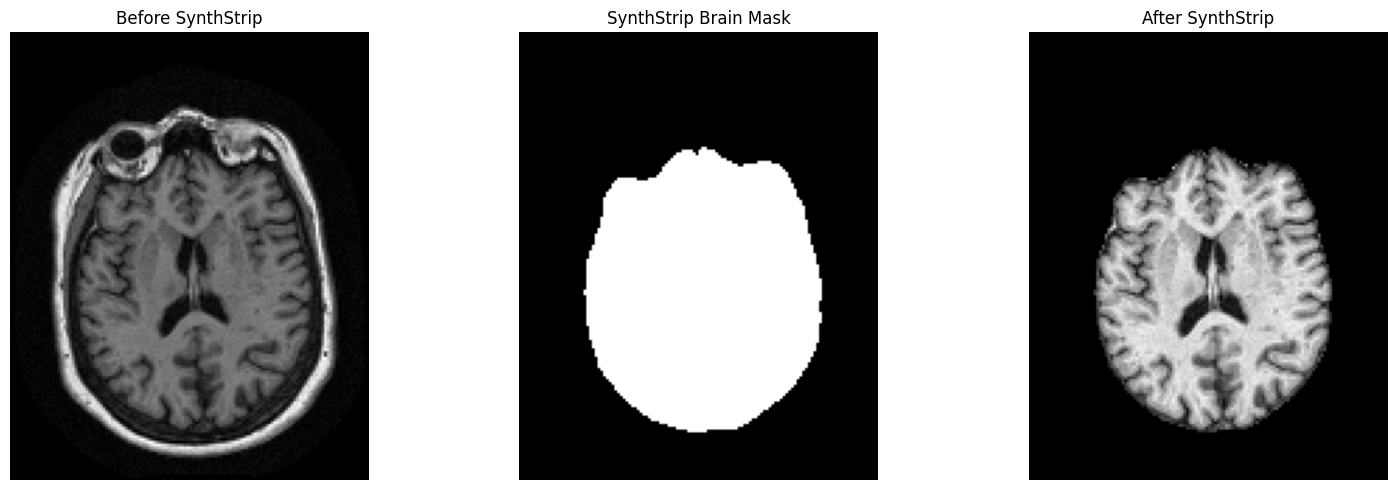

In [ ]:
# Choose middle axial slice
z = original_data.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(
    np.rot90(original_data[:, :, z]),
    cmap="gray"
)
axes[0].set_title("Before SynthStrip")

axes[1].imshow(
    np.rot90(brain_mask[:, :, z]),
    cmap="gray"
)
axes[1].set_title("SynthStrip Brain Mask")

axes[2].imshow(
    np.rot90(brain_data[:, :, z]),
    cmap="gray"
)
axes[2].set_title("After SynthStrip")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 12A: BRAIN-ONLY INTENSITY NORMALIZATION
# ============================================================

brain_data = brain_data.astype(np.float32)
brain_mask = brain_mask > 0

# Extract only brain voxels
brain_values = brain_data[brain_mask]

print("Brain voxels:", len(brain_values))

print("\nBefore normalization:")
print("Minimum :", brain_values.min())
print("Maximum :", brain_values.max())
print("Mean    :", brain_values.mean())
print("STD     :", brain_values.std())

Brain voxels: 412212

Before normalization:
Minimum : 0.0
Maximum : 919.3931
Mean    : 343.34888
STD     : 144.64372


In [ ]:
# ============================================================
# STEP 12B: PERCENTILE CLIPPING
# ============================================================

p1, p99 = np.percentile(brain_values, [1, 99])

print("1st percentile :", p1)
print("99th percentile:", p99)

clipped = np.clip(brain_data, p1, p99)

1st percentile : 32.64336498260498
99th percentile: 553.4598864746093


In [ ]:
# ============================================================
# STEP 12C: Z-SCORE NORMALIZATION
# ============================================================

normalized_data = np.zeros_like(clipped, dtype=np.float32)

normalized_brain_values = clipped[brain_mask]

mean = normalized_brain_values.mean()
std = normalized_brain_values.std()

normalized_data[brain_mask] = (
    (clipped[brain_mask] - mean) / (std + 1e-8)
)

print("After normalization:")
print("Mean:", normalized_data[brain_mask].mean())
print("STD :", normalized_data[brain_mask].std())
print("Min :", normalized_data[brain_mask].min())
print("Max :", normalized_data[brain_mask].max())

After normalization:
Mean: -1.5517463e-07
STD : 0.9999999
Min : -2.154584
Max : 1.4573854


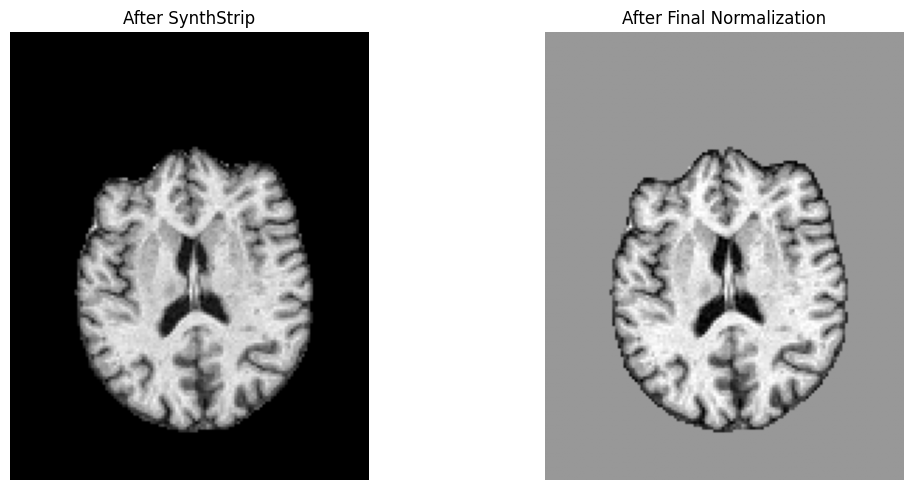

In [ ]:
# ============================================================
# STEP 12D: VISUALIZE FINAL NORMALIZED MRI
# ============================================================

z = normalized_data.shape[2] // 2

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    np.rot90(brain_data[:, :, z]),
    cmap="gray"
)
axes[0].set_title("After SynthStrip")

axes[1].imshow(
    np.rot90(normalized_data[:, :, z]),
    cmap="gray"
)
axes[1].set_title("After Final Normalization")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 12E: VERIFY SYNTHSTRIP MASK
# ============================================================

mask_values = brain_data[brain_mask]

print("Total masked voxels:", len(mask_values))
print("Zero-valued voxels inside mask:", np.sum(mask_values == 0))
print(
    "Percentage of zero voxels inside mask:",
    round(100 * np.mean(mask_values == 0), 4),
    "%"
)

print("\nMask unique values:")
print(np.unique(brain_mask))

Total masked voxels: 412212
Zero-valued voxels inside mask: 98
Percentage of zero voxels inside mask: 0.0238 %

Mask unique values:
[False  True]


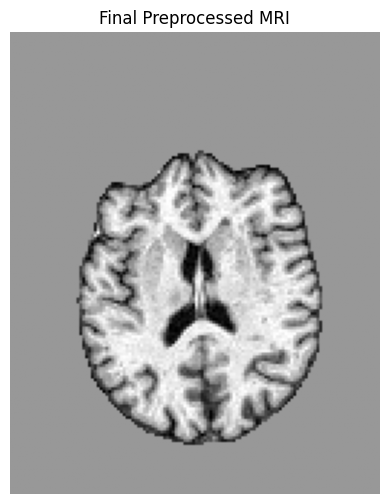

In [ ]:
# ============================================================
# STEP 12F: FINAL NORMALIZED MRI
# ============================================================

z = normalized_data.shape[2] // 2

plt.figure(figsize=(6, 6))

plt.imshow(
    np.rot90(normalized_data[:, :, z]),
    cmap="gray"
)

plt.title("Final Preprocessed MRI")
plt.axis("off")
plt.show()


In [ ]:
# ============================================================
# STEP 13A: IDENTIFY INFORMATIVE AXIAL SLICES
# ============================================================

brain_pixels_per_slice = brain_mask.sum(axis=(0, 1))

max_brain_area = brain_pixels_per_slice.max()

# Keep slices containing at least 40% of maximum brain area
threshold = 0.40 * max_brain_area

informative_slices = np.where(
    brain_pixels_per_slice >= threshold
)[0]

print("Maximum brain area :", max_brain_area)
print("40% threshold      :", threshold)

print("First informative slice:",
      informative_slices[0])

print("Last informative slice:",
      informative_slices[-1])

print("Number of informative slices:",
      len(informative_slices))

Maximum brain area : 6813
40% threshold      : 2725.2000000000003
First informative slice: 38
Last informative slice: 108
Number of informative slices: 71


In [ ]:
# ============================================================
# STEP 13B: SELECT 32 INFORMATIVE AXIAL SLICES
# ============================================================

NUM_SLICES = 32

positions = np.linspace(
    0,
    len(informative_slices) - 1,
    NUM_SLICES
).round().astype(int)

selected_slices = informative_slices[positions]

print("Selected slices:")
print(selected_slices)

print("\nNumber of selected slices:",
      len(selected_slices))

Selected slices:
[ 38  40  43  45  47  49  52  54  56  58  61  63  65  67  70  72  74  76
  79  81  83  85  88  90  92  94  97  99 101 103 106 108]

Number of selected slices: 32


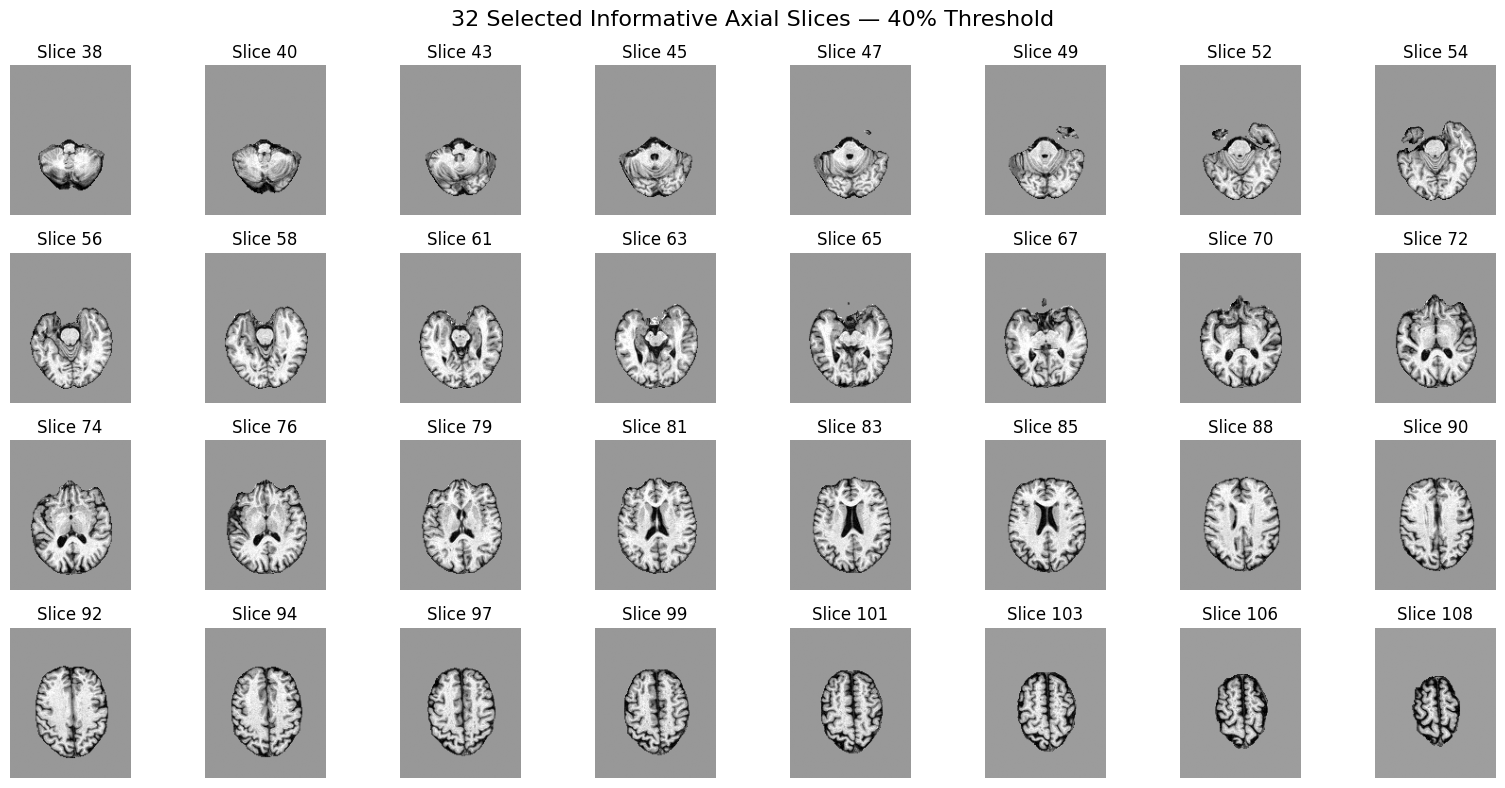

In [ ]:
# ============================================================
# STEP 13C: VISUALIZE 32 SELECTED SLICES
# ============================================================

fig, axes = plt.subplots(
    4, 8,
    figsize=(16, 8)
)

for ax, slice_idx in zip(
    axes.ravel(),
    selected_slices
):
    ax.imshow(
        np.rot90(normalized_data[:, :, slice_idx]),
        cmap="gray"
    )

    ax.set_title(f"Slice {slice_idx}")
    ax.axis("off")

plt.suptitle(
    "32 Selected Informative Axial Slices — 40% Threshold",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 14A: RESIZE TO 224×224 WITHOUT DISTORTING MRI
# ============================================================

from scipy.ndimage import zoom
import numpy as np
import matplotlib.pyplot as plt

TARGET_SIZE = 224

resized_slices = []

for slice_idx in selected_slices:

    # Extract axial slice
    slice_2d = normalized_data[:, :, slice_idx]

    h, w = slice_2d.shape

    # Same scale for both dimensions
    scale = min(
        TARGET_SIZE / h,
        TARGET_SIZE / w
    )

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    # Preserve aspect ratio
    resized = zoom(
        slice_2d,
        (scale, scale),
        order=1
    )

    # Make sure dimensions are exactly calculated size
    resized = resized[:new_h, :new_w]

    # Create 224×224 canvas
    canvas = np.zeros(
        (TARGET_SIZE, TARGET_SIZE),
        dtype=np.float32
    )

    # Center the resized MRI
    top = (TARGET_SIZE - new_h) // 2
    left = (TARGET_SIZE - new_w) // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized

    resized_slices.append(canvas)

resized_slices = np.array(
    resized_slices,
    dtype=np.float32
)

print("Original slice shape:",
      normalized_data[:, :, selected_slices[0]].shape)

print("Final dataset shape:",
      resized_slices.shape)

print("Data type:",
      resized_slices.dtype)

Original slice shape: (128, 160)
Final dataset shape: (32, 224, 224)
Data type: float32


In [ ]:
# ============================================================
# STEP 14B: VALIDATE RESIZED SLICES
# ============================================================

print("Shape :", resized_slices.shape)
print("Min   :", resized_slices.min())
print("Max   :", resized_slices.max())
print("Mean  :", resized_slices.mean())
print("STD   :", resized_slices.std())
print("NaN   :", np.isnan(resized_slices).sum())
print("Inf   :", np.isinf(resized_slices).sum())

Shape : (32, 224, 224)
Min   : -2.154584
Max   : 1.4573854
Mean  : 0.011132897
STD   : 0.418804
NaN   : 0
Inf   : 0


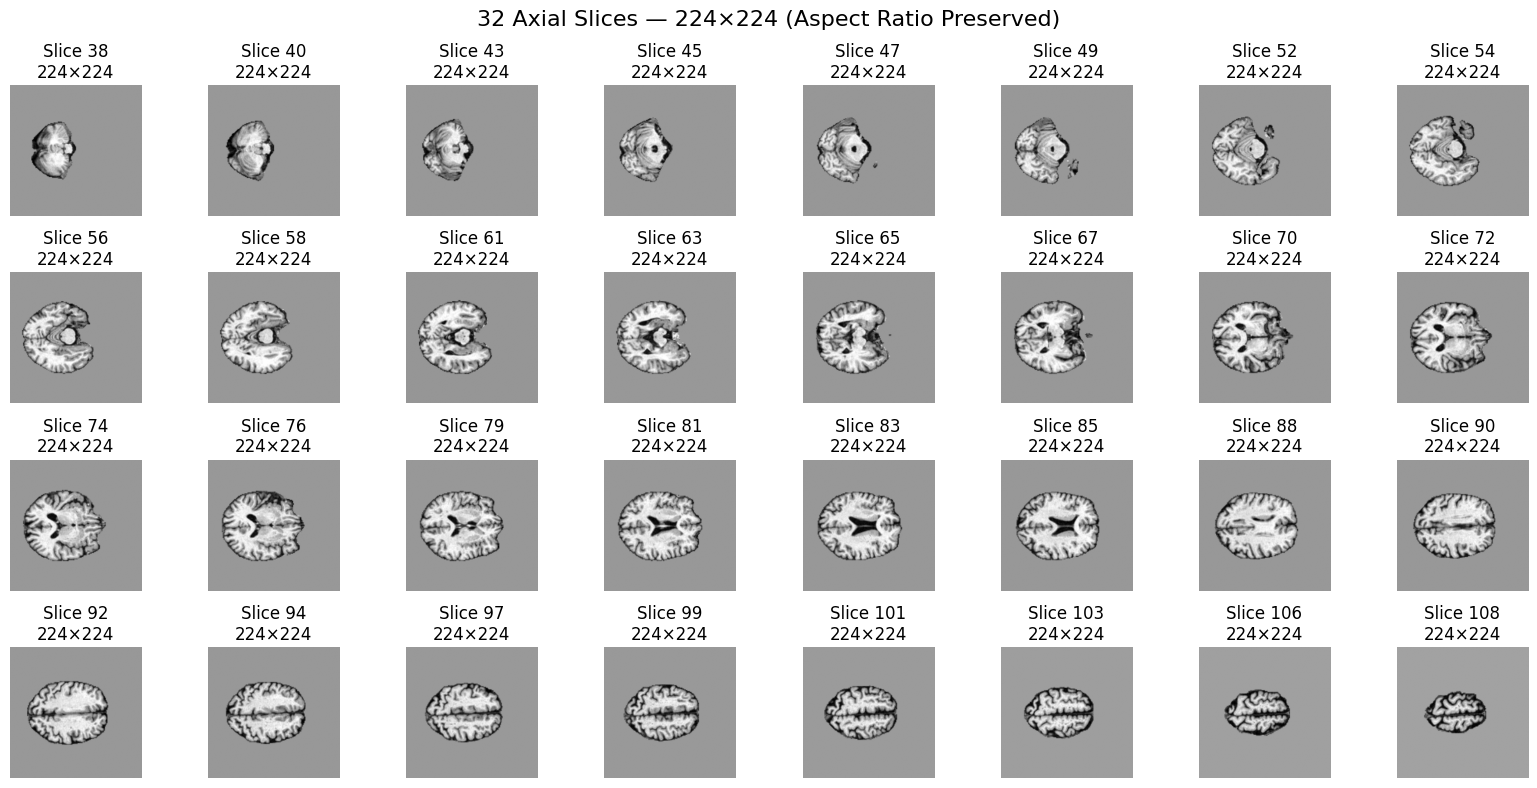

In [ ]:
# ============================================================
# STEP 14C: VISUALIZE ASPECT-RATIO-PRESERVED SLICES
# ============================================================

fig, axes = plt.subplots(
    4, 8,
    figsize=(16, 8)
)

for ax, image, slice_idx in zip(
    axes.ravel(),
    resized_slices,
    selected_slices
):

    ax.imshow(
        image,
        cmap="gray"
    )

    ax.set_title(
        f"Slice {slice_idx}\n224×224"
    )

    ax.axis("off")

plt.suptitle(
    "32 Axial Slices — 224×224 "
    "(Aspect Ratio Preserved)",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 15A: ASPECT-RATIO-PRESERVING RESIZE FUNCTION
# ============================================================

from scipy.ndimage import zoom
import numpy as np
import matplotlib.pyplot as plt

TARGET_SIZE = 224

def resize_preserve_aspect(slice_2d, target_size=224):
    """
    Resize a 2D MRI slice while preserving aspect ratio.
    Remaining area is zero-padded.
    """

    h, w = slice_2d.shape

    # Same scale for both dimensions
    scale = min(
        target_size / h,
        target_size / w
    )

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    # Resize
    resized = zoom(
        slice_2d,
        (scale, scale),
        order=1
    )

    # Create zero-padded canvas
    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.float32
    )

    # Center image
    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized[:new_h, :new_w]

    return canvas

In [ ]:
# ============================================================
# STEP 15B: CREATE ONE 2.5D SAMPLE
# ============================================================

# Choose a middle selected slice
center_position = len(selected_slices) // 2

center_slice = selected_slices[center_position]

previous_slice = center_slice - 1
next_slice = center_slice + 1

print("Previous slice:", previous_slice)
print("Center slice  :", center_slice)
print("Next slice    :", next_slice)

# Extract actual neighboring slices
channel_1 = normalized_data[:, :, previous_slice]
channel_2 = normalized_data[:, :, center_slice]
channel_3 = normalized_data[:, :, next_slice]

# Resize each channel
channel_1 = resize_preserve_aspect(channel_1)
channel_2 = resize_preserve_aspect(channel_2)
channel_3 = resize_preserve_aspect(channel_3)

# Stack as RGB-style 3-channel image
sample_2_5D = np.stack(
    [channel_1, channel_2, channel_3],
    axis=-1
)

print("\n2.5D sample shape:", sample_2_5D.shape)
print("Data type:", sample_2_5D.dtype)
print("NaN:", np.isnan(sample_2_5D).sum())
print("Inf:", np.isinf(sample_2_5D).sum())

Previous slice: 73
Center slice  : 74
Next slice    : 75

2.5D sample shape: (224, 224, 3)
Data type: float32
NaN: 0
Inf: 0


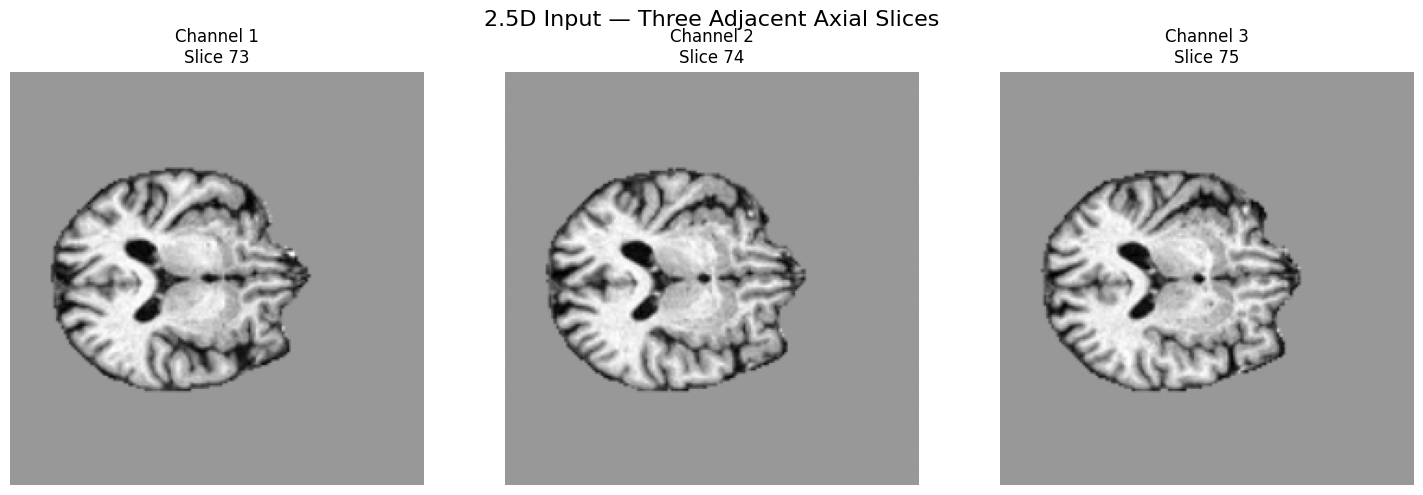

In [ ]:
# ============================================================
# STEP 15C: VISUALIZE 2.5D CHANNELS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

axes[0].imshow(
    sample_2_5D[:, :, 0],
    cmap="gray"
)
axes[0].set_title(
    f"Channel 1\nSlice {previous_slice}"
)

axes[1].imshow(
    sample_2_5D[:, :, 1],
    cmap="gray"
)
axes[1].set_title(
    f"Channel 2\nSlice {center_slice}"
)

axes[2].imshow(
    sample_2_5D[:, :, 2],
    cmap="gray"
)
axes[2].set_title(
    f"Channel 3\nSlice {next_slice}"
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    "2.5D Input — Three Adjacent Axial Slices",
    fontsize=16
)

plt.tight_layout()
plt.show()

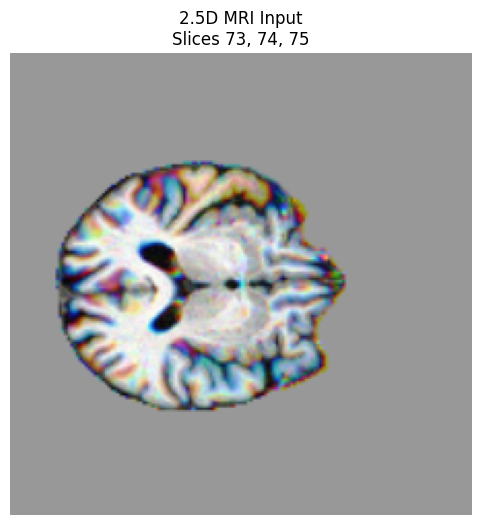

In [ ]:
# ============================================================
# STEP 15D: VISUALIZE 2.5D IMAGE
# ============================================================

# Normalize only for visualization
vis_image = sample_2_5D.copy()

vis_min = vis_image.min()
vis_max = vis_image.max()

vis_image = (
    (vis_image - vis_min) /
    (vis_max - vis_min + 1e-8)
)

plt.figure(figsize=(6, 6))

plt.imshow(vis_image)

plt.title(
    f"2.5D MRI Input\n"
    f"Slices {previous_slice}, {center_slice}, {next_slice}"
)

plt.axis("off")
plt.show()

In [ ]:
# ============================================================
# STEP 16A: COMPLETE PREPROCESSING SETUP
# ============================================================

import os
import zipfile
import shutil
import subprocess
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.ndimage import zoom
from tqdm.auto import tqdm

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

ZIP_PATH = "/content/drive/MyDrive/Alzheimer_Project.zip"

WORK_DIR = "/content/alzheimer_work"
EXTRACT_DIR = os.path.join(WORK_DIR, "Alzheimer_Project")

OUTPUT_DIR = "/content/drive/MyDrive/Alzheimer_Preprocessed"

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("ZIP exists:", os.path.exists(ZIP_PATH))
print("Output directory:", OUTPUT_DIR)

# ------------------------------------------------------------
# SYNTHSTRIP
# ------------------------------------------------------------

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"
MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

print("SynthStrip exists:", os.path.isfile(SYNTHSTRIP))
print("Model exists:", os.path.isfile(MODEL_PATH))

# ------------------------------------------------------------
# IMPORTANT LIBRARIES
# ------------------------------------------------------------

import surfa as sf

print("Surfa version:", sf.__version__)
print("NumPy version:", np.__version__)

ZIP exists: True
Output directory: /content/drive/MyDrive/Alzheimer_Preprocessed
SynthStrip exists: True
Model exists: False
Surfa version: 0.6.3
NumPy version: 1.26.4


In [ ]:
# ============================================================
# RESTORE SYNTHSTRIP MODEL
# ============================================================

import os

synth_dir = "/content/freesurfer/mri_synthstrip"

print("SynthStrip directory exists:",
      os.path.isdir(synth_dir))

print("\nFiles currently inside:")
if os.path.isdir(synth_dir):
    for f in os.listdir(synth_dir):
        print(f)

SynthStrip directory exists: True

Files currently inside:
Dockerfile.gpu
testdata.tar.gz
synthstrip.1.pt
synthstrip-singularity
CMakeLists.txt
synthstrip.nocsf.1.pt
readme.md
test.sh
synthstrip-docker
mri_synthstrip
Dockerfile.cpu


In [ ]:
# ============================================================
# VERIFY SYNTHSTRIP MODEL
# ============================================================

import os

MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"
SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"

print("SynthStrip executable:", os.path.isfile(SYNTHSTRIP))
print("Model exists:", os.path.isfile(MODEL_PATH))

if os.path.isfile(MODEL_PATH):
    size_mb = os.path.getsize(MODEL_PATH) / (1024 * 1024)
    print(f"Model size: {size_mb:.2f} MB")

SynthStrip executable: True
Model exists: False


In [ ]:
# ============================================================
# DIAGNOSE SYNTHSTRIP MODEL FILE
# ============================================================

import os
import subprocess

model_path = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

print("Path:", model_path)
print("exists():", os.path.exists(model_path))
print("isfile():", os.path.isfile(model_path))
print("islink():", os.path.islink(model_path))
print("lexists():", os.path.lexists(model_path))

print("\n--- ls -l ---")
subprocess.run(
    ["ls", "-lah", "/content/freesurfer/mri_synthstrip/"],
    check=False
)

print("\n--- file command ---")
subprocess.run(
    ["file", model_path],
    check=False
)

print("\n--- readlink ---")
subprocess.run(
    ["readlink", "-f", model_path],
    check=False
)

Path: /content/freesurfer/mri_synthstrip/synthstrip.1.pt
exists(): False
isfile(): False
islink(): True
lexists(): True

--- ls -l ---

--- file command ---

--- readlink ---


CompletedProcess(args=['readlink', '-f', '/content/freesurfer/mri_synthstrip/synthstrip.1.pt'], returncode=1)

In [ ]:
# ============================================================
# FIX SYNTHSTRIP MODEL
# ============================================================

import os

model_path = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

# Remove broken symbolic link
if os.path.lexists(model_path):
    os.remove(model_path)

print("Broken model link removed:", not os.path.lexists(model_path))

Broken model link removed: True


In [ ]:
# Download actual SynthStrip model
!wget -q \
https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt \
-O /content/freesurfer/mri_synthstrip/synthstrip.1.pt

In [ ]:
import os

model_path = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

print("Exists:", os.path.exists(model_path))
print("Is file:", os.path.isfile(model_path))
print("Is symlink:", os.path.islink(model_path))

if os.path.isfile(model_path):
    print(
        "Size:",
        round(os.path.getsize(model_path) / (1024**2), 2),
        "MB"
    )

Exists: True
Is file: True
Is symlink: False
Size: 29.42 MB


In [ ]:
# ============================================================
# STEP 16: FINAL SYNTHSTRIP PATHS
# ============================================================

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"
MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

print("SynthStrip:", os.path.isfile(SYNTHSTRIP))
print("Model:", os.path.isfile(MODEL_PATH))

SynthStrip: True
Model: True


In [ ]:
# ============================================================
# STEP 16B: CLEAN EXTRACTION OF COMPLETE DATASET
# ============================================================

import os
import shutil
import zipfile

ZIP_PATH = "/content/drive/MyDrive/Alzheimer_Project.zip"

WORK_DIR = "/content/alzheimer_work_complete"
EXTRACT_DIR = os.path.join(
    WORK_DIR,
    "Alzheimer_Project"
)

# Start with a completely fresh extraction directory
if os.path.exists(WORK_DIR):
    shutil.rmtree(WORK_DIR)

os.makedirs(WORK_DIR, exist_ok=True)

print("Extracting ZIP...")
print("ZIP:", ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(WORK_DIR)

print("Extraction completed.")

# ------------------------------------------------------------
# CHECK IMPORTANT DIRECTORIES
# ------------------------------------------------------------

print("\nProject directory exists:",
      os.path.isdir(EXTRACT_DIR))

metadata_dir = os.path.join(
    EXTRACT_DIR,
    "Metadata"
)

dataset_dir = os.path.join(
    EXTRACT_DIR,
    "Dataset",
    "ADNI"
)

print("Metadata directory exists:",
      os.path.isdir(metadata_dir))

print("ADNI directory exists:",
      os.path.isdir(dataset_dir))

Extracting ZIP...
ZIP: /content/drive/MyDrive/Alzheimer_Project.zip
Extraction completed.

Project directory exists: True
Metadata directory exists: True
ADNI directory exists: True


In [ ]:
# ============================================================
# STEP 16C: VERIFY METADATA FILES
# ============================================================

print("Files inside Metadata:\n")

for f in os.listdir(metadata_dir):
    print(f)

Files inside Metadata:

ADNI_MRI_inventory.csv
ADNI_labels.csv


In [ ]:
LABELS_PATH = os.path.join(
    metadata_dir,
    "ADNI_labels.csv"
)

INVENTORY_PATH = os.path.join(
    metadata_dir,
    "ADNI_MRI_inventory.csv"
)

print("\nLabels exists:", os.path.isfile(LABELS_PATH))
print("Inventory exists:", os.path.isfile(INVENTORY_PATH))


Labels exists: True
Inventory exists: True


In [ ]:
# ============================================================
# STEP 16D: VERIFY NIFTI FILE COUNT
# ============================================================

nii_files = []

for root, dirs, files in os.walk(dataset_dir):

    for file in files:

        if file.lower().endswith(".nii") or \
           file.lower().endswith(".nii.gz"):

            nii_files.append(
                os.path.join(root, file)
            )

print("Total NIfTI files:", len(nii_files))

Total NIfTI files: 630


In [ ]:
# ============================================================
# STEP 16E: LOAD METADATA
# ============================================================

import pandas as pd

labels = pd.read_csv(LABELS_PATH)
inventory = pd.read_csv(INVENTORY_PATH)

print("Labels shape   :", labels.shape)
print("Inventory shape:", inventory.shape)

print("\nLabels columns:")
print(labels.columns.tolist())

print("\nInventory columns:")
print(inventory.columns.tolist())

print("\nFirst 5 label records:")
display(labels.head())

print("\nFirst 5 inventory records:")
display(inventory.head())

Labels shape   : (630, 12)
Inventory shape: (630, 14)

Labels columns:
['Image Data ID', 'Subject', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'Downloaded']

Inventory columns:
['Subject', 'Image_Data_ID', 'MRI_File_Name', 'MRI_Path', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'Downloaded']

First 5 label records:


,Image Data ID,Subject,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded
0,I63896,941_S_1363,MCI,F,70,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/12/2007,NiFTI,NaN
1,I97326,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,NaN
2,I97331,941_S_1311,MCI,M,69,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,3/02/2007,NiFTI,NaN
3,I63887,941_S_1295,MCI,M,77,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2/09/2007,NiFTI,NaN
4,I63878,941_S_1203,CN,M,83,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,1/29/2007,NiFTI,NaN



First 5 inventory records:


,Subject,Image_Data_ID,MRI_File_Name,MRI_Path,Group,Sex,Age,Visit,Modality,Description,Type,Acq Date,Format,Downloaded
0,002_S_0295,I45107,ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0295\M...,CN,M,85,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-04-18,NiFTI,NaN
1,002_S_0413,I45116,ADNI_002_S_0413_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0413\M...,CN,F,76,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-05-02,NiFTI,NaN
2,002_S_0559,I40673,ADNI_002_S_0559_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0559\M...,CN,M,79,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-05-23,NiFTI,NaN
3,002_S_0685,I40682,ADNI_002_S_0685_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0685\M...,CN,F,90,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-07-06,NiFTI,NaN
4,002_S_0729,I40707,ADNI_002_S_0729_MR_MPR__GradWarp__B1_Correctio...,D:\Alzheimer_Project\Dataset\ADNI\002_S_0729\M...,MCI,F,65,sc,MRI,MPR; GradWarp; B1 Correction; N3,Pre-processed,2006-07-17,NiFTI,NaN


In [ ]:
# ============================================================
# FIND EXISTING SUBJECT-WISE SPLIT FILE
# ============================================================

import os

search_roots = [
    "/content/drive/MyDrive",
    "/content/alzheimer_work_complete"
]

matches = []

for root_dir in search_roots:
    if not os.path.exists(root_dir):
        continue

    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file == "metadata_subjectwise_split.csv":
                matches.append(
                    os.path.join(root, file)
                )

print("Found split files:")

for path in matches:
    print(path)

print("\nNumber found:", len(matches))

Found split files:
/content/drive/MyDrive/metadata_subjectwise_split.csv

Number found: 1


In [ ]:
# ============================================================
# STEP 16F: LOAD EXISTING SUBJECT-WISE SPLIT
# ============================================================

SPLIT_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"

metadata = pd.read_csv(SPLIT_PATH)

print("Metadata shape:", metadata.shape)

print("\nColumns:")
print(metadata.columns.tolist())

print("\nSplit distribution:")
print(metadata["Split"].value_counts())

print("\nSplit × Group:")
print(
    pd.crosstab(
        metadata["Split"],
        metadata["Group"]
    )
)

print("\nUnique subjects:",
      metadata["Subject"].nunique())

print("\nSubjects per split:")
print(
    metadata.groupby("Split")["Subject"].nunique()
)

Metadata shape: (630, 14)

Columns:
['Image Data ID', 'Subject', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'MRI_File_Name', 'MRI_Path', 'Split']

Split distribution:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47

Unique subjects: 610

Subjects per split:
Split
test           92
train         427
validation     91
Name: Subject, dtype: int64


In [ ]:
# ============================================================
# STEP 16G: BUILD FINAL MRI PROCESSING TABLE
# ============================================================

processing_df = inventory.copy()

processing_df["Image_ID"] = (
    processing_df["Image_Data_ID"].astype(str)
)

# Attach actual NIfTI path
processing_df["NIfTI_Path"] = (
    processing_df["Image_ID"].map(nii_map)
)

# Attach subject-wise split
split_map = (
    metadata[
        ["Subject", "Split"]
    ]
    .drop_duplicates("Subject")
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("Total MRI records:",
      len(processing_df))

print("MRI paths found:",
      processing_df["NIfTI_Path"].notna().sum())

print("Missing MRI paths:",
      processing_df["NIfTI_Path"].isna().sum())

print("Missing splits:",
      processing_df["Split"].isna().sum())

print("\nSplit distribution:")
print(processing_df["Split"].value_counts())

print("\nSplit × Group:")
print(
    pd.crosstab(
        processing_df["Split"],
        processing_df["Group"]
    )
)

Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0

Split distribution:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47


In [ ]:
# ============================================================
# STEP 16G: FINAL SUBJECT LEAKAGE CHECK
# ============================================================

train_subjects = set(
    metadata.loc[
        metadata["Split"] == "train",
        "Subject"
    ]
)

val_subjects = set(
    metadata.loc[
        metadata["Split"] == "validation",
        "Subject"
    ]
)

test_subjects = set(
    metadata.loc[
        metadata["Split"] == "test",
        "Subject"
    ]
)

print("Train ∩ Validation:", len(train_subjects & val_subjects))
print("Train ∩ Test      :", len(train_subjects & test_subjects))
print("Validation ∩ Test :", len(val_subjects & test_subjects))

Train ∩ Validation: 0
Train ∩ Test      : 0
Validation ∩ Test : 0


In [ ]:
# ============================================================
# STEP 16H: BUILD FINAL MRI PROCESSING TABLE
# ============================================================

processing_df = inventory.copy()

processing_df["Image_ID"] = (
    processing_df["Image_Data_ID"].astype(str)
)

# Attach actual Colab NIfTI path
processing_df["NIfTI_Path"] = (
    processing_df["Image_ID"].map(nii_map)
)

# Attach subject-wise split
split_map = (
    metadata[
        ["Subject", "Split"]
    ]
    .drop_duplicates("Subject")
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

print("Total MRI records:",
      len(processing_df))

print("MRI paths found:",
      processing_df["NIfTI_Path"].notna().sum())

print("Missing MRI paths:",
      processing_df["NIfTI_Path"].isna().sum())

print("Missing splits:",
      processing_df["Split"].isna().sum())

print("\nSplit × Group:")
print(
    pd.crosstab(
        processing_df["Split"],
        processing_df["Group"]
    )
)

Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47


In [ ]:
# ============================================================
# STEP 16I-1: REDEFINE COMPLETE PREPROCESSING FUNCTIONS
# ============================================================

import os
import subprocess
import numpy as np
import nibabel as nib
from scipy.ndimage import zoom

TARGET_SIZE = 224
NUM_SLICES = 32
BRAIN_THRESHOLD = 0.40

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"
MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"


# ------------------------------------------------------------
# 1. Resize while preserving aspect ratio
# ------------------------------------------------------------

def resize_preserve_aspect(slice_2d, target_size=224):

    h, w = slice_2d.shape

    scale = min(
        target_size / h,
        target_size / w
    )

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    resized = zoom(
        slice_2d,
        (scale, scale),
        order=1
    )

    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.float32
    )

    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized[:new_h, :new_w]

    return canvas


# ------------------------------------------------------------
# 2. Select 32 informative slices
# ------------------------------------------------------------

def select_informative_slices(
    mask,
    num_slices=32
):

    brain_area = np.sum(
        mask,
        axis=(0, 1)
    )

    max_area = brain_area.max()

    threshold = (
        BRAIN_THRESHOLD *
        max_area
    )

    informative = np.where(
        brain_area >= threshold
    )[0]

    if len(informative) < num_slices:

        raise ValueError(
            f"Only {len(informative)} "
            f"informative slices found."
        )

    positions = np.linspace(
        0,
        len(informative) - 1,
        num_slices
    ).round().astype(int)

    selected = informative[positions]

    return selected


# ------------------------------------------------------------
# 3. Create 2.5D samples
# ------------------------------------------------------------

def create_2_5d_samples(
    normalized_data,
    selected_slices
):

    samples = []

    depth = normalized_data.shape[2]

    for center_slice in selected_slices:

        previous_slice = max(
            0,
            center_slice - 1
        )

        next_slice = min(
            depth - 1,
            center_slice + 1
        )

        channel_1 = normalized_data[
            :, :, previous_slice
        ]

        channel_2 = normalized_data[
            :, :, center_slice
        ]

        channel_3 = normalized_data[
            :, :, next_slice
        ]

        channel_1 = resize_preserve_aspect(
            channel_1
        )

        channel_2 = resize_preserve_aspect(
            channel_2
        )

        channel_3 = resize_preserve_aspect(
            channel_3
        )

        sample = np.stack(
            [
                channel_1,
                channel_2,
                channel_3
            ],
            axis=-1
        ).astype(np.float32)

        samples.append(sample)

    return np.array(
        samples,
        dtype=np.float32
    )


# ------------------------------------------------------------
# 4. Complete preprocessing for one MRI
# ------------------------------------------------------------

def preprocess_one_mri(mri_path):

    # --------------------------------------------------------
    # Load MRI
    # --------------------------------------------------------

    img = nib.load(mri_path)

    # --------------------------------------------------------
    # RAS orientation
    # --------------------------------------------------------

    img = nib.as_closest_canonical(img)

    data = img.get_fdata(
        dtype=np.float32
    )

    current_shape = np.array(
        data.shape[:3]
    )

    current_zooms = np.array(
        img.header.get_zooms()[:3]
    )

    # --------------------------------------------------------
    # Resample to 1.5 mm isotropic
    # --------------------------------------------------------

    target_spacing = np.array(
        [1.5, 1.5, 1.5]
    )

    new_shape = np.round(
        current_shape *
        current_zooms /
        target_spacing
    ).astype(int)

    zoom_factors = (
        new_shape /
        current_shape
    )

    resampled_data = zoom(
        data,
        zoom_factors,
        order=1
    ).astype(np.float32)

    # --------------------------------------------------------
    # Save temporary resampled MRI
    # --------------------------------------------------------

    temp_input = (
        "/content/temp_input.nii.gz"
    )

    temp_brain = (
        "/content/temp_brain.nii.gz"
    )

    temp_mask = (
        "/content/temp_mask.nii.gz"
    )

    affine = np.diag([
        1.5,
        1.5,
        1.5,
        1
    ])

    resampled_img = nib.Nifti1Image(
        resampled_data,
        affine
    )

    nib.save(
        resampled_img,
        temp_input
    )

    # --------------------------------------------------------
    # SynthStrip
    # --------------------------------------------------------

    command = [
        "python",
        SYNTHSTRIP,
        "-i",
        temp_input,
        "-o",
        temp_brain,
        "-m",
        temp_mask,
        "--model",
        MODEL_PATH,
        "-t",
        "4"
    ]

    result = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:

        raise RuntimeError(
            "SynthStrip failed:\n" +
            result.stderr
        )

    # --------------------------------------------------------
    # Load brain + mask
    # --------------------------------------------------------

    brain_img = nib.load(
        temp_brain
    )

    mask_img = nib.load(
        temp_mask
    )

    brain = brain_img.get_fdata(
        dtype=np.float32
    )

    mask = (
        mask_img.get_fdata() > 0
    )

    # --------------------------------------------------------
    # Brain-only percentile clipping
    # --------------------------------------------------------

    brain_values = brain[mask]

    if len(brain_values) == 0:

        raise ValueError(
            "Brain mask contains no voxels."
        )

    p1, p99 = np.percentile(
        brain_values,
        [1, 99]
    )

    clipped = np.clip(
        brain,
        p1,
        p99
    )

    # --------------------------------------------------------
    # Brain-only Z-score normalization
    # --------------------------------------------------------

    brain_values = clipped[mask]

    mean = brain_values.mean()
    std = brain_values.std()

    if std == 0:

        raise ValueError(
            "Brain intensity STD is zero."
        )

    normalized = (
        clipped - mean
    ) / (std + 1e-8)

    normalized[~mask] = 0

    normalized = normalized.astype(
        np.float32
    )

    # --------------------------------------------------------
    # Select 32 informative slices
    # --------------------------------------------------------

    selected_slices = (
        select_informative_slices(
            mask,
            NUM_SLICES
        )
    )

    # --------------------------------------------------------
    # Create 2.5D samples
    # --------------------------------------------------------

    samples = create_2_5d_samples(
        normalized,
        selected_slices
    )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    for file_path in [
        temp_input,
        temp_brain,
        temp_mask
    ]:

        if os.path.exists(file_path):
            os.remove(file_path)

    return samples, selected_slices


print("All preprocessing functions defined successfully.")

All preprocessing functions defined successfully.


In [ ]:
# ============================================================
# STEP 16I: TEST COMPLETE PREPROCESSING ON 5 MRIs
# ============================================================

test_records = processing_df.head(5)

test_results = []

for _, row in tqdm(
    test_records.iterrows(),
    total=len(test_records),
    desc="Testing 5 MRIs"
):

    try:
        samples, selected = preprocess_one_mri(
            row["NIfTI_Path"]
        )

        test_results.append({
            "Image_ID": row["Image_ID"],
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": samples.shape,
            "Selected_Slices": len(selected),
            "NaN": np.isnan(samples).sum(),
            "Inf": np.isinf(samples).sum(),
            "Status": "OK"
        })

    except Exception as e:

        test_results.append({
            "Image_ID": row["Image_ID"],
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": None,
            "Selected_Slices": None,
            "NaN": None,
            "Inf": None,
            "Status": str(e)
        })

test_df = pd.DataFrame(test_results)

display(test_df)

Testing 5 MRIs:   0%|          | 0/5 [00:00<?, ?it/s]

,Image_ID,Subject,Group,Split,Shape,Selected_Slices,NaN,Inf,Status
0,I45107,002_S_0295,CN,train,None,None,None,None,name 'preprocess_one_mri' is not defined
1,I45116,002_S_0413,CN,train,None,None,None,None,name 'preprocess_one_mri' is not defined
2,I40673,002_S_0559,CN,test,None,None,None,None,name 'preprocess_one_mri' is not defined
3,I40682,002_S_0685,CN,train,None,None,None,None,name 'preprocess_one_mri' is not defined
4,I40707,002_S_0729,MCI,train,None,None,None,None,name 'preprocess_one_mri' is not defined


In [ ]:
# ============================================================
# STEP 16I-2: TEST COMPLETE PIPELINE ON 5 MRIs
# ============================================================

test_records = processing_df.head(5)

test_results = []

for _, row in tqdm(
    test_records.iterrows(),
    total=len(test_records),
    desc="Testing 5 MRIs"
):

    try:

        samples, selected = preprocess_one_mri(
            row["NIfTI_Path"]
        )

        test_results.append({
            "Image_ID": row["Image_ID"],
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": samples.shape,
            "Selected_Slices": len(selected),
            "NaN": np.isnan(samples).sum(),
            "Inf": np.isinf(samples).sum(),
            "Status": "OK"
        })

    except Exception as e:

        test_results.append({
            "Image_ID": row["Image_ID"],
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": None,
            "Selected_Slices": None,
            "NaN": None,
            "Inf": None,
            "Status": str(e)
        })

test_df = pd.DataFrame(test_results)

display(test_df)

Testing 5 MRIs:   0%|          | 0/5 [00:00<?, ?it/s]

,Image_ID,Subject,Group,Split,Shape,Selected_Slices,NaN,Inf,Status
0,I45107,002_S_0295,CN,train,"(32, 224, 224, 3)",32,0,0,OK
1,I45116,002_S_0413,CN,train,"(32, 224, 224, 3)",32,0,0,OK
2,I40673,002_S_0559,CN,test,"(32, 224, 224, 3)",32,0,0,OK
3,I40682,002_S_0685,CN,train,"(32, 224, 224, 3)",32,0,0,OK
4,I40707,002_S_0729,MCI,train,"(32, 224, 224, 3)",32,0,0,OK


In [ ]:
# ============================================================
# STEP 17A: CREATE SAFE OUTPUT STRUCTURE
# ============================================================

import os
import pandas as pd
import numpy as np

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

TRAIN_DIR = os.path.join(OUTPUT_ROOT, "train")
VAL_DIR   = os.path.join(OUTPUT_ROOT, "validation")
TEST_DIR  = os.path.join(OUTPUT_ROOT, "test")

for directory in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    os.makedirs(directory, exist_ok=True)

PROGRESS_PATH = os.path.join(
    OUTPUT_ROOT,
    "preprocessing_progress.csv"
)

print("Output root:", OUTPUT_ROOT)
print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)
print("Progress file:", PROGRESS_PATH)

Output root: /content/drive/MyDrive/Alzheimer_Preprocessed
Train directory: /content/drive/MyDrive/Alzheimer_Preprocessed/train
Validation directory: /content/drive/MyDrive/Alzheimer_Preprocessed/validation
Test directory: /content/drive/MyDrive/Alzheimer_Preprocessed/test
Progress file: /content/drive/MyDrive/Alzheimer_Preprocessed/preprocessing_progress.csv


In [ ]:
# ============================================================
# STEP 17B: CREATE RESUME-SAFE PROCESSING LIST
# ============================================================

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        row["Split"],
        f'{row["Image_ID"]}.npz'
    ),
    axis=1
)

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(
        os.path.isfile
    )
)

print("Total MRIs:",
      len(processing_df))

print(
    "Already processed:",
    processing_df["Already_Processed"].sum()
)

print(
    "Remaining:",
    (~processing_df["Already_Processed"]).sum()
)

print("\nSplit-wise status:")

print(
    processing_df.groupby(
        ["Split", "Already_Processed"]
    ).size()
)

Total MRIs: 630
Already processed: 0
Remaining: 630

Split-wise status:
Split       Already_Processed
test        False                 92
train       False                443
validation  False                 95
dtype: int64


In [ ]:
# ============================================================
# STEP 17C: SELECT FIRST 10 UNPROCESSED MRIs
# ============================================================

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

test_batch = pending_df.head(10).copy()

print("Testing batch size:", len(test_batch))

display(
    test_batch[
        [
            "Image_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

Testing batch size: 10


,Image_ID,Subject,Group,Split
0,I45107,002_S_0295,CN,train
1,I45116,002_S_0413,CN,train
2,I40673,002_S_0559,CN,test
3,I40682,002_S_0685,CN,train
4,I40707,002_S_0729,MCI,train
5,I40716,002_S_0782,MCI,train
6,I40730,002_S_0816,AD,train
7,I40979,002_S_0938,AD,validation
8,I40739,002_S_0954,MCI,train
9,I40753,002_S_0955,AD,train


In [ ]:
# ============================================================
# STEP 17D: PROCESS AND SAVE 10-MRI TEST BATCH
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

batch_results = []

start_time = time.time()

for _, row in tqdm(
    test_batch.iterrows(),
    total=len(test_batch),
    desc="Processing 10-MRI batch"
):

    image_id = row["Image_ID"]
    output_path = row["Output_Path"]

    try:

        # Process MRI
        samples, selected_slices = preprocess_one_mri(
            row["NIfTI_Path"]
        )

        # Safety checks
        assert samples.shape == (32, 224, 224, 3)
        assert not np.isnan(samples).any()
        assert not np.isinf(samples).any()

        # Save processed data
        np.savez_compressed(
            output_path,
            data=samples.astype(np.float32),
            selected_slices=np.array(
                selected_slices,
                dtype=np.int16
            ),
            image_id=image_id,
            subject=row["Subject"],
            group=row["Group"],
            split=row["Split"]
        )

        batch_results.append({
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": str(samples.shape),
            "Selected_Slices": len(selected_slices),
            "NaN": int(np.isnan(samples).sum()),
            "Inf": int(np.isinf(samples).sum()),
            "Output_Exists": os.path.isfile(output_path),
            "Status": "OK"
        })

    except Exception as e:

        batch_results.append({
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Shape": None,
            "Selected_Slices": None,
            "NaN": None,
            "Inf": None,
            "Output_Exists": False,
            "Status": str(e)
        })


elapsed = time.time() - start_time

batch_df = pd.DataFrame(batch_results)

print("\n" + "=" * 60)
print("10-MRI BATCH COMPLETE")
print("=" * 60)

print(f"Time taken: {elapsed / 60:.2f} minutes")
print(
    f"Average time per MRI: "
    f"{elapsed / len(test_batch):.1f} seconds"
)

display(batch_df)

Processing 10-MRI batch:   0%|          | 0/10 [00:00<?, ?it/s]


10-MRI BATCH COMPLETE
Time taken: 13.89 minutes
Average time per MRI: 83.4 seconds


,Image_ID,Subject,Group,Split,Shape,Selected_Slices,NaN,Inf,Output_Exists,Status
0,I45107,002_S_0295,CN,train,"(32, 224, 224, 3)",32,0,0,True,OK
1,I45116,002_S_0413,CN,train,"(32, 224, 224, 3)",32,0,0,True,OK
2,I40673,002_S_0559,CN,test,"(32, 224, 224, 3)",32,0,0,True,OK
3,I40682,002_S_0685,CN,train,"(32, 224, 224, 3)",32,0,0,True,OK
4,I40707,002_S_0729,MCI,train,"(32, 224, 224, 3)",32,0,0,True,OK
5,I40716,002_S_0782,MCI,train,"(32, 224, 224, 3)",32,0,0,True,OK
6,I40730,002_S_0816,AD,train,"(32, 224, 224, 3)",32,0,0,True,OK
7,I40979,002_S_0938,AD,validation,"(32, 224, 224, 3)",32,0,0,True,OK
8,I40739,002_S_0954,MCI,train,"(32, 224, 224, 3)",32,0,0,True,OK
9,I40753,002_S_0955,AD,train,"(32, 224, 224, 3)",32,0,0,True,OK


In [ ]:
# ============================================================
# STEP 17E: VERIFY SAVED 10-MRI FILES
# ============================================================

print("Saved files:")

for _, row in test_batch.iterrows():

    path = row["Output_Path"]

    print(
        row["Image_ID"],
        "->",
        os.path.isfile(path),
        "->",
        os.path.getsize(path) / (1024 * 1024)
        if os.path.isfile(path) else 0,
        "MB"
    )

Saved files:
I45107 -> True -> 4.189499855041504 MB
I45116 -> True -> 4.352100372314453 MB
I40673 -> True -> 4.604156494140625 MB
I40682 -> True -> 4.5389909744262695 MB
I40707 -> True -> 4.055936813354492 MB
I40716 -> True -> 4.276063919067383 MB
I40730 -> True -> 4.502988815307617 MB
I40979 -> True -> 4.159308433532715 MB
I40739 -> True -> 3.793471336364746 MB
I40753 -> True -> 4.06068229675293 MB


In [ ]:
# ============================================================
# VERIFY ONE SAVED NPZ
# ============================================================

sample_path = test_batch.iloc[0]["Output_Path"]

loaded = np.load(
    sample_path,
    allow_pickle=True
)

data = loaded["data"]

print("File:", sample_path)
print("Loaded shape:", data.shape)
print("Data type:", data.dtype)
print("NaN:", np.isnan(data).sum())
print("Inf:", np.isinf(data).sum())
print("Image ID:", loaded["image_id"])
print("Subject:", loaded["subject"])
print("Group:", loaded["group"])
print("Split:", loaded["split"])

File: /content/drive/MyDrive/Alzheimer_Preprocessed/train/I45107.npz
Loaded shape: (32, 224, 224, 3)
Data type: float32
NaN: 0
Inf: 0
Image ID: I45107
Subject: 002_S_0295
Group: CN
Split: train


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("WARNING: GPU is not available.")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
# ============================================================
# STEP 18C: RECONNECT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
# ============================================================
# STEP 18D: VERIFY PROJECT + PROCESSED DATA
# ============================================================

import os
import glob

PROJECT_ZIP = "/content/drive/MyDrive/Alzheimer_Project.zip"
OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

print("Project ZIP exists:",
      os.path.isfile(PROJECT_ZIP))

print("Preprocessed directory exists:",
      os.path.isdir(OUTPUT_ROOT))

processed_files = glob.glob(
    os.path.join(
        OUTPUT_ROOT,
        "**",
        "*.npz"
    ),
    recursive=True
)

print("Processed NPZ files:", len(processed_files))

print("\nFirst few files:")

for f in processed_files[:10]:
    print(f)

Project ZIP exists: True
Preprocessed directory exists: True
Processed NPZ files: 10

First few files:
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I45107.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I45116.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40682.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40707.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40716.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40730.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40739.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/train/I40753.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/validation/I40979.npz
/content/drive/MyDrive/Alzheimer_Preprocessed/test/I40673.npz


In [ ]:
# ============================================================
# STEP 18E: RESTORE DATASET METADATA + NIFTI PATHS
# ============================================================

import os
import zipfile
import glob
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PROJECT_ZIP = "/content/drive/MyDrive/Alzheimer_Project.zip"

WORK_DIR = "/content/alzheimer_work"
EXTRACT_DIR = os.path.join(
    WORK_DIR,
    "Alzheimer_Project"
)

METADATA_DIR = os.path.join(
    EXTRACT_DIR,
    "Metadata"
)

DATASET_DIR = os.path.join(
    EXTRACT_DIR,
    "Dataset",
    "ADNI"
)

LABELS_PATH = os.path.join(
    METADATA_DIR,
    "ADNI_labels.csv"
)

INVENTORY_PATH = os.path.join(
    METADATA_DIR,
    "ADNI_MRI_inventory.csv"
)

SPLIT_PATH = (
    "/content/drive/MyDrive/"
    "metadata_subjectwise_split.csv"
)

# ------------------------------------------------------------
# VERIFY EXTRACTION
# ------------------------------------------------------------

print("Project directory:",
      os.path.isdir(EXTRACT_DIR))

print("Metadata directory:",
      os.path.isdir(METADATA_DIR))

print("ADNI directory:",
      os.path.isdir(DATASET_DIR))

# ------------------------------------------------------------
# LOAD METADATA
# ------------------------------------------------------------

labels = pd.read_csv(
    LABELS_PATH
)

inventory = pd.read_csv(
    INVENTORY_PATH
)

split_df = pd.read_csv(
    SPLIT_PATH
)

print("\nLabels:", labels.shape)
print("Inventory:", inventory.shape)
print("Split:", split_df.shape)

# ------------------------------------------------------------
# FIND BOTH .nii AND .nii.gz
# ------------------------------------------------------------

nii_files = []

for root, dirs, files in os.walk(DATASET_DIR):

    for file in files:

        if (
            file.lower().endswith(".nii")
            or
            file.lower().endswith(".nii.gz")
        ):

            nii_files.append(
                os.path.join(root, file)
            )

print("\nNIfTI files found:", len(nii_files))

# ------------------------------------------------------------
# BUILD FILENAME → PATH MAP
# ------------------------------------------------------------

nii_map = {}

for path in nii_files:

    filename = os.path.basename(path)

    nii_map[filename] = path

print(
    "Unique NIfTI filenames:",
    len(nii_map)
)

# ------------------------------------------------------------
# CREATE PROCESSING DATAFRAME
# ------------------------------------------------------------

processing_df = inventory.copy()

# Actual MRI filename from inventory
processing_df["NIfTI_Path"] = (
    processing_df["MRI_File_Name"]
    .map(nii_map)
)

# ------------------------------------------------------------
# ATTACH SUBJECT-WISE SPLIT
# ------------------------------------------------------------

split_map = (
    split_df[
        ["Subject", "Split"]
    ]
    .drop_duplicates(
        subset=["Subject"]
    )
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROCESSING DATASET VALIDATION")
print("=" * 60)

print(
    "Total MRI records:",
    len(processing_df)
)

print(
    "MRI paths found:",
    processing_df["NIfTI_Path"].notna().sum()
)

print(
    "Missing MRI paths:",
    processing_df["NIfTI_Path"].isna().sum()
)

print(
    "Missing splits:",
    processing_df["Split"].isna().sum()
)

print("\nSplit distribution:")

print(
    processing_df["Split"].value_counts()
)

print("\nSplit × Group:")

print(
    pd.crosstab(
        processing_df["Split"],
        processing_df["Group"]
    )
)

# ------------------------------------------------------------
# SHOW FIRST 5
# ------------------------------------------------------------

print("\nFirst 5 records:")

display(
    processing_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "MRI_File_Name",
            "NIfTI_Path",
            "Split"
        ]
    ].head()
)

Project directory: True
Metadata directory: True
ADNI directory: True

Labels: (630, 12)
Inventory: (630, 14)
Split: (630, 14)

NIfTI files found: 630
Unique NIfTI filenames: 630

PROCESSING DATASET VALIDATION
Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0

Split distribution:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47

First 5 records:


,Image_Data_ID,Subject,Group,MRI_File_Name,NIfTI_Path,Split
0,I45107,002_S_0295,CN,ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correctio...,/content/alzheimer_work/Alzheimer_Project/Data...,train
1,I45116,002_S_0413,CN,ADNI_002_S_0413_MR_MPR__GradWarp__B1_Correctio...,/content/alzheimer_work/Alzheimer_Project/Data...,train
2,I40673,002_S_0559,CN,ADNI_002_S_0559_MR_MPR__GradWarp__B1_Correctio...,/content/alzheimer_work/Alzheimer_Project/Data...,test
3,I40682,002_S_0685,CN,ADNI_002_S_0685_MR_MPR__GradWarp__B1_Correctio...,/content/alzheimer_work/Alzheimer_Project/Data...,train
4,I40707,002_S_0729,MCI,ADNI_002_S_0729_MR_MPR__GradWarp__B1_Correctio...,/content/alzheimer_work/Alzheimer_Project/Data...,train


In [ ]:
# ============================================================
# STEP 18F: RESTORE SYNTHSTRIP FOR THIS GPU RUNTIME
# ============================================================

import os
import subprocess

SYNTH_DIR = "/content/freesurfer/mri_synthstrip"

os.makedirs(SYNTH_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    SYNTH_DIR,
    "synthstrip.1.pt"
)

SCRIPT_PATH = os.path.join(
    SYNTH_DIR,
    "mri_synthstrip"
)

# ------------------------------------------------------------
# Download SynthStrip model
# ------------------------------------------------------------

if not os.path.isfile(MODEL_PATH):

    print("Downloading SynthStrip model...")

    subprocess.run([
        "wget", "-q",
        "https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt",
        "-O",
        MODEL_PATH
    ], check=True)

# ------------------------------------------------------------
# Download official SynthStrip Python script
# ------------------------------------------------------------

if not os.path.isfile(SCRIPT_PATH):

    print("Downloading SynthStrip script...")

    subprocess.run([
        "wget", "-q",
        "https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/mri_synthstrip",
        "-O",
        SCRIPT_PATH
    ], check=True)

    os.chmod(
        SCRIPT_PATH,
        0o755
    )

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\nSynthStrip executable:",
      os.path.isfile(SCRIPT_PATH))

print("SynthStrip model:",
      os.path.isfile(MODEL_PATH))

if os.path.isfile(MODEL_PATH):

    size_mb = (
        os.path.getsize(MODEL_PATH)
        / (1024 ** 2)
    )

    print(
        f"Model size: {size_mb:.2f} MB"
    )


SynthStrip executable: True
SynthStrip model: True
Model size: 29.42 MB


In [ ]:
# ============================================================
# STEP 18G: VERIFY SURFA
# ============================================================

try:
    import surfa
    print("Surfa version:", surfa.__version__)
except ImportError:
    print("Surfa is not installed.")

Surfa is not installed.


In [ ]:
# ============================================================
# STEP 18G: INSTALL SURFA
# ============================================================

!pip install -q surfa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 5.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import surfa
import numpy as np

print("Surfa version:", surfa.__version__)
print("NumPy version:", np.__version__)

Surfa version: 0.6.3
NumPy version: 2.0.2


In [ ]:
# ============================================================
# STEP 18H: FIX NUMPY COMPATIBILITY
# ============================================================

!pip install -q "numpy==1.26.4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 47.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is

In [ ]:
import numpy as np
import torch

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NumPy: 1.26.4
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


In [ ]:
!pip install -q "surfa==0.6.3"

In [ ]:
import surfa

print("Surfa version:", surfa.__version__)

Surfa version: 0.6.3


In [ ]:
# ============================================================
# RESTORE SYNTHSTRIP
# ============================================================

import os
import subprocess

SYNTH_DIR = "/content/freesurfer/mri_synthstrip"

os.makedirs(SYNTH_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    SYNTH_DIR,
    "synthstrip.1.pt"
)

SCRIPT_PATH = os.path.join(
    SYNTH_DIR,
    "mri_synthstrip"
)

# Download model
if not os.path.isfile(MODEL_PATH):

    subprocess.run([
        "wget", "-q",
        "https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt",
        "-O",
        MODEL_PATH
    ], check=True)

# Download script
if not os.path.isfile(SCRIPT_PATH):

    subprocess.run([
        "wget", "-q",
        "https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/mri_synthstrip",
        "-O",
        SCRIPT_PATH
    ], check=True)

    os.chmod(SCRIPT_PATH, 0o755)

print("SynthStrip:", os.path.isfile(SCRIPT_PATH))
print("Model:", os.path.isfile(MODEL_PATH))

if os.path.isfile(MODEL_PATH):
    print(
        "Model size:",
        round(os.path.getsize(MODEL_PATH) / (1024**2), 2),
        "MB"
    )

SynthStrip: True
Model: True
Model size: 29.42 MB


In [ ]:
# ============================================================
# STEP 18K: RESTORE PROCESSING DATAFRAME
# ============================================================

import os
import pandas as pd

SPLIT_PATH = "/content/drive/MyDrive/metadata_subjectwise_split.csv"
INVENTORY_PATH = "/content/alzheimer_work/Alzheimer_Project/Metadata/ADNI_MRI_inventory.csv"
DATASET_DIR = "/content/alzheimer_work/Alzheimer_Project/Dataset/ADNI"

# Load inventory and split
inventory = pd.read_csv(INVENTORY_PATH)
split_df = pd.read_csv(SPLIT_PATH)

# Find all NIfTI files
nii_map = {}

for root, dirs, files in os.walk(DATASET_DIR):

    for file in files:

        if file.lower().endswith(".nii") or \
           file.lower().endswith(".nii.gz"):

            nii_map[file] = os.path.join(
                root,
                file
            )

# Build processing dataframe
processing_df = inventory.copy()

processing_df["NIfTI_Path"] = (
    processing_df["MRI_File_Name"]
    .map(nii_map)
)

# Attach subject-wise split
split_map = (
    split_df[
        ["Subject", "Split"]
    ]
    .drop_duplicates("Subject")
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

print("Total MRI records:",
      len(processing_df))

print("MRI paths found:",
      processing_df["NIfTI_Path"].notna().sum())

print("Missing MRI paths:",
      processing_df["NIfTI_Path"].isna().sum())

print("Missing splits:",
      processing_df["Split"].isna().sum())

Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0


In [ ]:
# ============================================================
# STEP 18L: SELECT ONE TEST MRI
# ============================================================

TEST_IMAGE_ID = "I45107"

test_row = processing_df[
    processing_df["Image_Data_ID"].astype(str)
    == TEST_IMAGE_ID
].iloc[0]

TEST_MRI = test_row["NIfTI_Path"]

print("Image ID:", TEST_IMAGE_ID)
print("Subject:", test_row["Subject"])
print("Group:", test_row["Group"])
print("Split:", test_row["Split"])
print("MRI path:", TEST_MRI)
print("Input exists:", os.path.isfile(TEST_MRI))

Image ID: I45107
Subject: 002_S_0295
Group: CN
Split: train
MRI path: /content/alzheimer_work/Alzheimer_Project/Dataset/ADNI/002_S_0295/MPR__GradWarp__B1_Correction__N3/2006-04-18_08_20_30.0/I45107/ADNI_002_S_0295_MR_MPR__GradWarp__B1_Correction__N3_Br_20070319113435616_S13408_I45107.nii
Input exists: True


In [ ]:
# ============================================================
# STEP 18L: GPU SYNTHSTRIP BENCHMARK — 1 MRI
# ============================================================

import os
import shutil
import subprocess
import time

GPU_INPUT = "/content/gpu_test_input.nii"
GPU_BRAIN = "/content/gpu_test_brain.nii.gz"
GPU_MASK = "/content/gpu_test_mask.nii.gz"

# Copy test MRI
shutil.copy2(TEST_MRI, GPU_INPUT)

print("Input exists:", os.path.isfile(GPU_INPUT))

# ------------------------------------------------------------
# Run SynthStrip using GPU
# ------------------------------------------------------------

start_time = time.time()

result = subprocess.run(
    [
        "python",
        SCRIPT_PATH,
        "-i", GPU_INPUT,
        "-o", GPU_BRAIN,
        "-m", GPU_MASK,
        "--model", MODEL_PATH,
        "-g"
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

elapsed = time.time() - start_time

print("\nReturn code:", result.returncode)
print("Time taken:", round(elapsed, 2), "seconds")

print("Brain output exists:",
      os.path.isfile(GPU_BRAIN))

print("Mask output exists:",
      os.path.isfile(GPU_MASK))

if result.returncode != 0:
    print("\n--- SynthStrip ERROR ---")
    print(result.stderr)
else:
    print("\nSynthStrip GPU test successful! ✅")

Input exists: True

Return code: 0
Time taken: 75.31 seconds
Brain output exists: True
Mask output exists: True

SynthStrip GPU test successful! ✅


In [ ]:
# ============================================================
# STEP 19A: MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("\nGoogle Drive mounted successfully.")

Mounted at /content/drive

Google Drive mounted successfully.


In [ ]:
import os

print("Files/folders in MyDrive:")
for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Files/folders in MyDrive:
Colab Notebooks
Untitled document (2).gdoc
SBL_PPT.pptx
Untitled presentation (6).gslides
Resume_Analyzer_ppt.pptx
iot poster.pptx
Template PPT for book report (1).gslides
Untitled presentation (5).gslides
Motion in straight line_1.gslides
Untitled presentation (4).gslides
Untitled presentation (3).gslides
Indian-Legal-Awareness-Chatbot-for-Common-Citizens.gslides
Untitled presentation (2).gslides
Untitled presentation (1).gslides
Physics_Vectors_CET.gslides
Untitled presentation.gslides
Resume_Vikas_Gupta_2.pdf
Untitled document (1).gdoc
Untitled document.gdoc
resnet50_alzheimers_best.keras
dataset_2d.zip
Alzheimer_Project.zip
metadata_subjectwise_split.csv
Alzheimer_Preprocessed


In [ ]:
# ============================================================
# STEP 19A: RESTORE PROJECT + PROCESSING DATAFRAME
# ============================================================

import os
import zipfile
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PROJECT_ZIP = "/content/drive/MyDrive/Alzheimer_Project.zip"

WORK_DIR = "/content/alzheimer_work"
EXTRACT_DIR = os.path.join(
    WORK_DIR,
    "Alzheimer_Project"
)

METADATA_DIR = os.path.join(
    EXTRACT_DIR,
    "Metadata"
)

DATASET_DIR = os.path.join(
    EXTRACT_DIR,
    "Dataset",
    "ADNI"
)

INVENTORY_PATH = os.path.join(
    METADATA_DIR,
    "ADNI_MRI_inventory.csv"
)

SPLIT_PATH = (
    "/content/drive/MyDrive/"
    "metadata_subjectwise_split.csv"
)

OUTPUT_ROOT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Preprocessed"
)

# ------------------------------------------------------------
# Extract project
# ------------------------------------------------------------

if not os.path.isdir(EXTRACT_DIR):

    print("Extracting Alzheimer_Project.zip...")

    os.makedirs(WORK_DIR, exist_ok=True)

    with zipfile.ZipFile(
        PROJECT_ZIP,
        "r"
    ) as z:

        z.extractall(WORK_DIR)

    print("Extraction completed.")

else:

    print("Project already extracted.")

# ------------------------------------------------------------
# Verify paths
# ------------------------------------------------------------

print("\nProject directory:",
      os.path.isdir(EXTRACT_DIR))

print("Metadata directory:",
      os.path.isdir(METADATA_DIR))

print("ADNI directory:",
      os.path.isdir(DATASET_DIR))

print("Inventory exists:",
      os.path.isfile(INVENTORY_PATH))

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

inventory = pd.read_csv(
    INVENTORY_PATH
)

split_df = pd.read_csv(
    SPLIT_PATH
)

print("\nInventory shape:",
      inventory.shape)

print("Split shape:",
      split_df.shape)

# ------------------------------------------------------------
# Find NIfTI files
# ------------------------------------------------------------

nii_map = {}

for root, dirs, files in os.walk(
    DATASET_DIR
):

    for file in files:

        if (
            file.lower().endswith(".nii")
            or
            file.lower().endswith(".nii.gz")
        ):

            nii_map[file] = os.path.join(
                root,
                file
            )

print("\nNIfTI files found:",
      len(nii_map))

# ------------------------------------------------------------
# Build processing dataframe
# ------------------------------------------------------------

processing_df = inventory.copy()

processing_df["NIfTI_Path"] = (
    processing_df["MRI_File_Name"]
    .map(nii_map)
)

# ------------------------------------------------------------
# Add subject-wise split
# ------------------------------------------------------------

split_map = (
    split_df[
        ["Subject", "Split"]
    ]
    .drop_duplicates(
        subset=["Subject"]
    )
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROCESSING DATASET READY")
print("=" * 60)

print(
    "Total MRI records:",
    len(processing_df)
)

print(
    "MRI paths found:",
    processing_df["NIfTI_Path"].notna().sum()
)

print(
    "Missing MRI paths:",
    processing_df["NIfTI_Path"].isna().sum()
)

print(
    "Missing splits:",
    processing_df["Split"].isna().sum()
)

print("\nSplit distribution:")

print(
    processing_df["Split"].value_counts()
)

print("\nSplit × Group:")

print(
    pd.crosstab(
        processing_df["Split"],
        processing_df["Group"]
    )
)

Extracting Alzheimer_Project.zip...
Extraction completed.

Project directory: True
Metadata directory: True
ADNI directory: True
Inventory exists: True

Inventory shape: (630, 14)
Split shape: (630, 14)

NIfTI files found: 630

PROCESSING DATASET READY
Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0

Split distribution:
Split
train         443
validation     95
test           92
Name: count, dtype: int64

Split × Group:
Group        AD   CN  MCI
Split                    
test         21   26   45
train       106  122  215
validation   22   26   47


In [ ]:
# ============================================================
# STEP 19B: CHECK ALREADY PROCESSED + CREATE NEXT BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# ------------------------------------------------------------
# Create output path for every MRI
# ------------------------------------------------------------

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# ------------------------------------------------------------
# Check whether each MRI is already processed
# ------------------------------------------------------------

processing_df["Already_Processed"] = (
    processing_df["Output_Path"]
    .apply(os.path.isfile)
)

# ------------------------------------------------------------
# Separate processed and pending MRIs
# ------------------------------------------------------------

pending_df = processing_df[
    processing_df["Already_Processed"] == False
].copy()

# ------------------------------------------------------------
# Select NEXT 10 MRIs
# ------------------------------------------------------------

batch_df = pending_df.head(10).copy()

# ------------------------------------------------------------
# Display status
# ------------------------------------------------------------

print("=" * 60)
print("STEP 19B COMPLETE")
print("=" * 60)

print(
    "Total MRIs:",
    len(processing_df)
)

print(
    "Already processed:",
    int(processing_df["Already_Processed"].sum())
)

print(
    "Remaining:",
    len(pending_df)
)

print(
    "\nBatch size:",
    len(batch_df)
)

print("\nRemaining by split:")

print(
    pending_df["Split"].value_counts()
)

print("\nNext batch:")

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19B COMPLETE
Total MRIs: 630
Already processed: 199
Remaining: 431

Batch size: 10

Remaining by split:
Split
train         299
test           66
validation     66
Name: count, dtype: int64

Next batch:


,Image_Data_ID,Subject,Group,Split
199,I34113,027_S_0118,CN,test
200,I34331,027_S_0120,CN,train
201,I34131,027_S_0179,MCI,train
202,I34149,027_S_0256,MCI,train
203,I34158,027_S_0307,MCI,train
204,I34176,027_S_0403,CN,train
205,I34203,027_S_0404,AD,train
206,I37547,027_S_0408,MCI,train
207,I34221,027_S_0417,MCI,test
208,I34230,027_S_0461,MCI,train


In [ ]:
def preprocess_one_mri(mri_path):

    # --------------------------------------------------------
    # Load MRI
    # --------------------------------------------------------

    img = nib.load(mri_path)

    # --------------------------------------------------------
    # RAS orientation
    # --------------------------------------------------------

    img = nib.as_closest_canonical(img)

    data = img.get_fdata(
        dtype=np.float32
    )

    current_shape = np.array(
        data.shape[:3]
    )

    current_zooms = np.array(
        img.header.get_zooms()[:3]
    )

    # --------------------------------------------------------
    # Resample to 1.5 mm isotropic
    # --------------------------------------------------------

    target_spacing = np.array(
        [1.5, 1.5, 1.5]
    )

    new_shape = np.round(
        current_shape *
        current_zooms /
        target_spacing
    ).astype(int)

    zoom_factors = (
        new_shape /
        current_shape
    )

    resampled_data = zoom(
        data,
        zoom_factors,
        order=1
    ).astype(np.float32)

    # --------------------------------------------------------
    # Save temporary resampled MRI
    # --------------------------------------------------------

    temp_input = "/content/temp_input.nii.gz"
    temp_brain = "/content/temp_brain.nii.gz"
    temp_mask = "/content/temp_mask.nii.gz"

    affine = np.diag([
        1.5,
        1.5,
        1.5,
        1
    ])

    resampled_img = nib.Nifti1Image(
        resampled_data,
        affine
    )

    nib.save(
        resampled_img,
        temp_input
    )

    # --------------------------------------------------------
    # SynthStrip — GPU
    # --------------------------------------------------------

    command = [
        "python",
        SYNTHSTRIP,
        "-i",
        temp_input,
        "-o",
        temp_brain,
        "-m",
        temp_mask,
        "--model",
        MODEL_PATH,
        "-t",
        "4",
        "-g"                 # USE GPU
    ]

    result = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:

        raise RuntimeError(
            "SynthStrip failed:\n" +
            result.stderr
        )

    # --------------------------------------------------------
    # Load brain + mask
    # --------------------------------------------------------

    brain_img = nib.load(
        temp_brain
    )

    mask_img = nib.load(
        temp_mask
    )

    brain = brain_img.get_fdata(
        dtype=np.float32
    )

    mask = (
        mask_img.get_fdata() > 0
    )

    # --------------------------------------------------------
    # Brain-only percentile clipping
    # --------------------------------------------------------

    brain_values = brain[mask]

    if len(brain_values) == 0:

        raise ValueError(
            "Brain mask contains no voxels."
        )

    p1, p99 = np.percentile(
        brain_values,
        [1, 99]
    )

    clipped = np.clip(
        brain,
        p1,
        p99
    )

    # --------------------------------------------------------
    # Brain-only Z-score normalization
    # --------------------------------------------------------

    brain_values = clipped[mask]

    mean = brain_values.mean()
    std = brain_values.std()

    if std == 0:

        raise ValueError(
            "Brain intensity STD is zero."
        )

    normalized = (
        clipped - mean
    ) / (std + 1e-8)

    normalized[~mask] = 0

    normalized = normalized.astype(
        np.float32
    )

    # --------------------------------------------------------
    # Select 32 informative slices
    # --------------------------------------------------------

    selected_slices = (
        select_informative_slices(
            mask,
            NUM_SLICES
        )
    )

    # --------------------------------------------------------
    # Create 2.5D samples
    # --------------------------------------------------------

    samples = create_2_5d_samples(
        normalized,
        selected_slices
    )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    for file_path in [
        temp_input,
        temp_brain,
        temp_mask
    ]:

        if os.path.exists(file_path):
            os.remove(file_path)

    return samples, selected_slices

In [ ]:
# ============================================================
# STEP 19C-1: REDEFINE SINGLE-MRI PROCESS + SAVE FUNCTION
# ============================================================

import os
import time
import numpy as np

def process_and_save_one(row):

    image_id = row["Image_Data_ID"]
    output_path = row["Output_Path"]

    # --------------------------------------------------------
    # Skip if already processed
    # --------------------------------------------------------

    if os.path.isfile(output_path):

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Status": "SKIPPED",
            "Output": output_path
        }

    # Make sure output directory exists
    os.makedirs(
        os.path.dirname(output_path),
        exist_ok=True
    )

    start = time.time()

    try:

        # ----------------------------------------------------
        # Run complete preprocessing
        # ----------------------------------------------------

        samples, selected_slices = (
            preprocess_one_mri(
                row["NIfTI_Path"]
            )
        )

        # ----------------------------------------------------
        # Validate
        # ----------------------------------------------------

        if samples.shape != (
            32,
            224,
            224,
            3
        ):

            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if np.isnan(samples).any():

            raise ValueError(
                "NaN detected"
            )

        if np.isinf(samples).any():

            raise ValueError(
                "Inf detected"
            )

        # ----------------------------------------------------
        # Save immediately to Google Drive
        # ----------------------------------------------------

        np.savez_compressed(
            output_path,
            data=samples.astype(
                np.float32
            ),
            selected_slices=np.asarray(
                selected_slices,
                dtype=np.int16
            ),
            image_id=str(image_id),
            subject=str(row["Subject"]),
            group=str(row["Group"]),
            split=str(row["Split"])
        )

        elapsed = time.time() - start

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Status": "OK",
            "Time_sec": round(
                elapsed,
                2
            ),
            "Output": output_path
        }

    except Exception as e:

        elapsed = time.time() - start

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Status": "ERROR",
            "Time_sec": round(
                elapsed,
                2
            ),
            "Error": str(e),
            "Output": output_path
        }


print(
    "process_and_save_one() defined:",
    callable(process_and_save_one)
)

process_and_save_one() defined: True


In [ ]:
# ============================================================
# FIX: IMPORT NIBABEL
# ============================================================

import nibabel as nib

print("Nibabel imported successfully.")

Nibabel imported successfully.


In [ ]:
# ============================================================
# FIX: IMPORT SCIPY ZOOM
# ============================================================

from scipy.ndimage import zoom

print("SciPy zoom imported successfully.")

SciPy zoom imported successfully.


In [ ]:
# ============================================================
# STEP 19A: RESTORE SYNTHSTRIP + MODEL
# ============================================================

import os
import subprocess

SYNTH_DIR = "/content/freesurfer/mri_synthstrip"

SYNTHSTRIP = os.path.join(
    SYNTH_DIR,
    "mri_synthstrip"
)

MODEL_PATH = os.path.join(
    SYNTH_DIR,
    "synthstrip.1.pt"
)

os.makedirs(SYNTH_DIR, exist_ok=True)

# ------------------------------------------------------------
# Download SynthStrip script
# ------------------------------------------------------------

if not os.path.isfile(SYNTHSTRIP):

    print("Downloading SynthStrip...")

    subprocess.run(
        [
            "wget",
            "-q",
            "https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/mri_synthstrip",
            "-O",
            SYNTHSTRIP
        ],
        check=True
    )

    os.chmod(SYNTHSTRIP, 0o755)

# ------------------------------------------------------------
# Download model
# ------------------------------------------------------------

if not os.path.isfile(MODEL_PATH):

    print("Downloading SynthStrip model...")

    subprocess.run(
        [
            "wget",
            "-q",
            "https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt",
            "-O",
            MODEL_PATH
        ],
        check=True
    )

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\nSynthStrip exists:",
      os.path.isfile(SYNTHSTRIP))

print("Model exists:",
      os.path.isfile(MODEL_PATH))

if os.path.isfile(MODEL_PATH):

    print(
        "Model size:",
        round(
            os.path.getsize(MODEL_PATH) / (1024 ** 2),
            2
        ),
        "MB"
    )


SynthStrip exists: True
Model exists: True
Model size: 29.42 MB


In [ ]:
# ============================================================
# FIX: RESTORE SYNTHSTRIP PATHS
# ============================================================

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"

MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

print("SynthStrip exists:",
      os.path.isfile(SYNTHSTRIP))

print("Model exists:",
      os.path.isfile(MODEL_PATH))

SynthStrip exists: True
Model exists: True


In [ ]:
# ============================================================
# STEP 19C-3: RESTORE SYNTHSTRIP
# ============================================================

import os
import subprocess

SYNTH_DIR = "/content/freesurfer/mri_synthstrip"

os.makedirs(SYNTH_DIR, exist_ok=True)

SYNTHSTRIP = os.path.join(
    SYNTH_DIR,
    "mri_synthstrip"
)

MODEL_PATH = os.path.join(
    SYNTH_DIR,
    "synthstrip.1.pt"
)

# ------------------------------------------------------------
# Download SynthStrip model
# ------------------------------------------------------------

if not os.path.isfile(MODEL_PATH):

    print("Downloading SynthStrip model...")

    subprocess.run(
        [
            "wget", "-q",
            "https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt",
            "-O",
            MODEL_PATH
        ],
        check=True
    )

# ------------------------------------------------------------
# Download SynthStrip executable/script
# ------------------------------------------------------------

if not os.path.isfile(SYNTHSTRIP):

    print("Downloading SynthStrip script...")

    subprocess.run(
        [
            "wget", "-q",
            "https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/mri_synthstrip",
            "-O",
            SYNTHSTRIP
        ],
        check=True
    )

    os.chmod(
        SYNTHSTRIP,
        0o755
    )

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\nSynthStrip exists:",
      os.path.isfile(SYNTHSTRIP))

print("Model exists:",
      os.path.isfile(MODEL_PATH))

if os.path.isfile(MODEL_PATH):

    print(
        "Model size:",
        round(
            os.path.getsize(MODEL_PATH)
            / (1024 ** 2),
            2
        ),
        "MB"
    )


SynthStrip exists: True
Model exists: True
Model size: 29.42 MB


In [ ]:
!pip install -q "surfa==0.6.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 5.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install -q "numpy==1.26.4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 75.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tifffile 2026.4.11 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have n

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
print("NumPy:", np.__version__)

NumPy: 1.26.4


In [ ]:
!pip install -q "surfa==0.6.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.5/105.5 kB 4.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import surfa
print("Surfa:", surfa.__version__)

Surfa: 0.6.3


In [ ]:
import numpy as np
import surfa
import torch

print("NumPy:", np.__version__)
print("Surfa:", surfa.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NumPy: 1.26.4
Surfa: 0.6.3
CUDA: True
GPU: Tesla T4


In [ ]:
# ============================================================
# COLAB ENVIRONMENT SETUP AFTER RUNTIME RESTART
# ============================================================

import os
import subprocess
import sys

# ------------------------------------------------------------
# 1. Check NumPy
# ------------------------------------------------------------

import numpy as np

print("NumPy:", np.__version__)

if np.__version__ != "1.26.4":
    print("Installing NumPy 1.26.4...")
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "numpy==1.26.4"
        ],
        check=True
    )

    print(
        "\nNumPy was changed."
        "\nPLEASE RESTART RUNTIME ONCE,"
        "\nthen run this setup cell again."
    )

else:
    print("NumPy version is correct.")


# ------------------------------------------------------------
# 2. Install Surfa
# ------------------------------------------------------------

print("\nInstalling/checking Surfa 0.6.3...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "surfa==0.6.3"
    ],
    check=True
)

# ------------------------------------------------------------
# 3. Import Surfa
# ------------------------------------------------------------

import surfa

print("Surfa:", surfa.__version__)


# ------------------------------------------------------------
# 4. Check PyTorch + GPU
# ------------------------------------------------------------

import torch

print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print("WARNING: GPU not available.")


# ------------------------------------------------------------
# 5. Restore SynthStrip
# ------------------------------------------------------------

SYNTH_DIR = "/content/freesurfer/mri_synthstrip"

os.makedirs(
    SYNTH_DIR,
    exist_ok=True
)

SYNTHSTRIP = os.path.join(
    SYNTH_DIR,
    "mri_synthstrip"
)

MODEL_PATH = os.path.join(
    SYNTH_DIR,
    "synthstrip.1.pt"
)


# ------------------------------------------------------------
# Download SynthStrip script if missing
# ------------------------------------------------------------

if not os.path.isfile(SYNTHSTRIP):

    print("\nDownloading SynthStrip...")

    subprocess.run(
        [
            "wget",
            "-q",
            "https://raw.githubusercontent.com/freesurfer/freesurfer/dev/mri_synthstrip/mri_synthstrip",
            "-O",
            SYNTHSTRIP
        ],
        check=True
    )

    os.chmod(
        SYNTHSTRIP,
        0o755
    )


# ------------------------------------------------------------
# Download model if missing
# ------------------------------------------------------------

if not os.path.isfile(MODEL_PATH):

    print("Downloading SynthStrip model...")

    subprocess.run(
        [
            "wget",
            "-q",
            "https://surfer.nmr.mgh.harvard.edu/pub/dist/freesurfer/synthstrip/models/synthstrip.1.pt",
            "-O",
            MODEL_PATH
        ],
        check=True
    )


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ENVIRONMENT CHECK")
print("=" * 60)

print(
    "NumPy:",
    np.__version__
)

print(
    "Surfa:",
    surfa.__version__
)

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print(
    "SynthStrip:",
    os.path.isfile(SYNTHSTRIP)
)

print(
    "Model:",
    os.path.isfile(MODEL_PATH)
)

if os.path.isfile(MODEL_PATH):

    size_mb = (
        os.path.getsize(MODEL_PATH)
        / (1024 ** 2)
    )

    print(
        "Model size:",
        round(size_mb, 2),
        "MB"
    )

NumPy: 1.26.4
NumPy version is correct.

Installing/checking Surfa 0.6.3...
Surfa: 0.6.3

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

ENVIRONMENT CHECK
NumPy: 1.26.4
Surfa: 0.6.3
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4
SynthStrip: True
Model: True
Model size: 29.42 MB


In [ ]:
# ============================================================
# STEP 19F: RESTORE PROJECT METADATA
# ============================================================

import os
import zipfile
import pandas as pd

PROJECT_ZIP = "/content/drive/MyDrive/Alzheimer_Project.zip"

WORK_DIR = "/content/alzheimer_work"
EXTRACT_DIR = os.path.join(
    WORK_DIR,
    "Alzheimer_Project"
)

METADATA_DIR = os.path.join(
    EXTRACT_DIR,
    "Metadata"
)

DATASET_DIR = os.path.join(
    EXTRACT_DIR,
    "Dataset",
    "ADNI"
)

INVENTORY_PATH = os.path.join(
    METADATA_DIR,
    "ADNI_MRI_inventory.csv"
)

SPLIT_PATH = (
    "/content/drive/MyDrive/"
    "metadata_subjectwise_split.csv"
)

OUTPUT_ROOT = (
    "/content/drive/MyDrive/"
    "Alzheimer_Preprocessed"
)

# ------------------------------------------------------------
# Extract project
# ------------------------------------------------------------

if not os.path.isdir(EXTRACT_DIR):

    print("Extracting Alzheimer_Project.zip...")

    os.makedirs(
        WORK_DIR,
        exist_ok=True
    )

    with zipfile.ZipFile(
        PROJECT_ZIP,
        "r"
    ) as z:

        z.extractall(WORK_DIR)

    print("Extraction completed.")

else:

    print("Project already extracted.")

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

inventory = pd.read_csv(
    INVENTORY_PATH
)

split_df = pd.read_csv(
    SPLIT_PATH
)

# ------------------------------------------------------------
# Find NIfTI files
# ------------------------------------------------------------

nii_map = {}

for root, dirs, files in os.walk(
    DATASET_DIR
):

    for file in files:

        if (
            file.lower().endswith(".nii")
            or
            file.lower().endswith(".nii.gz")
        ):

            nii_map[file] = os.path.join(
                root,
                file
            )

# ------------------------------------------------------------
# Build processing dataframe
# ------------------------------------------------------------

processing_df = inventory.copy()

processing_df["NIfTI_Path"] = (
    processing_df["MRI_File_Name"]
    .map(nii_map)
)

split_map = (
    split_df[
        ["Subject", "Split"]
    ]
    .drop_duplicates(
        subset=["Subject"]
    )
)

processing_df = processing_df.merge(
    split_map,
    on="Subject",
    how="left"
)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROJECT METADATA READY")
print("=" * 60)

print(
    "Total MRI records:",
    len(processing_df)
)

print(
    "MRI paths found:",
    processing_df["NIfTI_Path"].notna().sum()
)

print(
    "Missing MRI paths:",
    processing_df["NIfTI_Path"].isna().sum()
)

print(
    "Missing splits:",
    processing_df["Split"].isna().sum()
)

print("\nSplit distribution:")

print(
    processing_df["Split"].value_counts()
)

Project already extracted.

PROJECT METADATA READY
Total MRI records: 630
MRI paths found: 630
Missing MRI paths: 0
Missing splits: 0

Split distribution:
Split
train         443
validation     95
test           92
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 19G: CHECK EXISTING PROCESSED FILES
# ============================================================

import os
import numpy as np

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# Create output path
processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        row["Split"],
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# Check existing files
processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19G COMPLETE")
print("=" * 60)

print("Total MRIs:", len(processing_df))

print(
    "Already processed:",
    int(processing_df["Already_Processed"].sum())
)

print(
    "Remaining:",
    len(pending_df)
)

print("\nRemaining by split:")
print(
    pending_df["Split"].value_counts()
)

STEP 19G COMPLETE
Total MRIs: 630
Already processed: 199
Remaining: 431

Remaining by split:
Split
train         299
test           66
validation     66
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 19H: DEFINE COMPLETE MRI PREPROCESSING PIPELINE
# ============================================================

import os
import subprocess
import numpy as np
import nibabel as nib
from scipy.ndimage import zoom

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

TARGET_SIZE = 224
NUM_SLICES = 32
BRAIN_THRESHOLD = 0.40

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"
MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"

# ------------------------------------------------------------
# 1. Resize while preserving aspect ratio
# ------------------------------------------------------------

def resize_preserve_aspect(slice_2d, target_size=224):

    h, w = slice_2d.shape

    scale = min(
        target_size / h,
        target_size / w
    )

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    resized = zoom(
        slice_2d,
        (scale, scale),
        order=1
    )

    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.float32
    )

    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized[:new_h, :new_w]

    return canvas


# ------------------------------------------------------------
# 2. Select 32 informative slices
# ------------------------------------------------------------

def select_informative_slices(
    mask,
    num_slices=32
):

    brain_area = np.sum(
        mask,
        axis=(0, 1)
    )

    max_area = brain_area.max()

    threshold = (
        BRAIN_THRESHOLD *
        max_area
    )

    informative = np.where(
        brain_area >= threshold
    )[0]

    if len(informative) < num_slices:

        raise ValueError(
            f"Only {len(informative)} "
            f"informative slices found."
        )

    positions = np.linspace(
        0,
        len(informative) - 1,
        num_slices
    ).round().astype(int)

    selected = informative[positions]

    return selected


# ------------------------------------------------------------
# 3. Create 2.5D samples
# ------------------------------------------------------------

def create_2_5d_samples(
    normalized_data,
    selected_slices
):

    samples = []

    depth = normalized_data.shape[2]

    for center_slice in selected_slices:

        previous_slice = max(
            0,
            center_slice - 1
        )

        next_slice = min(
            depth - 1,
            center_slice + 1
        )

        channel_1 = normalized_data[
            :, :, previous_slice
        ]

        channel_2 = normalized_data[
            :, :, center_slice
        ]

        channel_3 = normalized_data[
            :, :, next_slice
        ]

        channel_1 = resize_preserve_aspect(
            channel_1,
            TARGET_SIZE
        )

        channel_2 = resize_preserve_aspect(
            channel_2,
            TARGET_SIZE
        )

        channel_3 = resize_preserve_aspect(
            channel_3,
            TARGET_SIZE
        )

        sample = np.stack(
            [
                channel_1,
                channel_2,
                channel_3
            ],
            axis=-1
        ).astype(np.float32)

        samples.append(sample)

    return np.array(
        samples,
        dtype=np.float32
    )


# ------------------------------------------------------------
# 4. Complete preprocessing for one MRI
# ------------------------------------------------------------

def preprocess_one_mri(mri_path):

    # --------------------------------------------------------
    # Load MRI
    # --------------------------------------------------------

    img = nib.load(mri_path)

    # --------------------------------------------------------
    # Convert to RAS orientation
    # --------------------------------------------------------

    img = nib.as_closest_canonical(img)

    data = img.get_fdata(
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Original shape and spacing
    # --------------------------------------------------------

    current_shape = np.array(
        data.shape[:3]
    )

    current_zooms = np.array(
        img.header.get_zooms()[:3]
    )

    # --------------------------------------------------------
    # Resample to 1.5 mm isotropic
    # --------------------------------------------------------

    target_spacing = np.array(
        [1.5, 1.5, 1.5]
    )

    new_shape = np.round(
        current_shape *
        current_zooms /
        target_spacing
    ).astype(int)

    zoom_factors = (
        new_shape /
        current_shape
    )

    resampled_data = zoom(
        data,
        zoom_factors,
        order=1
    ).astype(np.float32)

    # --------------------------------------------------------
    # Temporary files
    # --------------------------------------------------------

    temp_input = "/content/temp_input.nii.gz"
    temp_brain = "/content/temp_brain.nii.gz"
    temp_mask = "/content/temp_mask.nii.gz"

    affine = np.diag([
        1.5,
        1.5,
        1.5,
        1
    ])

    resampled_img = nib.Nifti1Image(
        resampled_data,
        affine
    )

    nib.save(
        resampled_img,
        temp_input
    )

    # --------------------------------------------------------
    # SynthStrip — GPU
    # --------------------------------------------------------

    command = [
        "python",
        SYNTHSTRIP,
        "-i",
        temp_input,
        "-o",
        temp_brain,
        "-m",
        temp_mask,
        "--model",
        MODEL_PATH,
        "-t",
        "4",
        "-g"
    ]

    result = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:

        # Cleanup before raising error
        for file_path in [
            temp_input,
            temp_brain,
            temp_mask
        ]:
            if os.path.exists(file_path):
                os.remove(file_path)

        raise RuntimeError(
            "SynthStrip failed:\n" +
            result.stderr
        )

    # --------------------------------------------------------
    # Load brain and mask
    # --------------------------------------------------------

    brain_img = nib.load(
        temp_brain
    )

    mask_img = nib.load(
        temp_mask
    )

    brain = brain_img.get_fdata(
        dtype=np.float32
    )

    mask = (
        mask_img.get_fdata() > 0
    )

    # --------------------------------------------------------
    # Brain-only percentile clipping
    # --------------------------------------------------------

    brain_values = brain[mask]

    if len(brain_values) == 0:

        raise ValueError(
            "Brain mask contains no voxels."
        )

    p1, p99 = np.percentile(
        brain_values,
        [1, 99]
    )

    clipped = np.clip(
        brain,
        p1,
        p99
    )

    # --------------------------------------------------------
    # Brain-only Z-score normalization
    # --------------------------------------------------------

    brain_values = clipped[mask]

    mean = brain_values.mean()
    std = brain_values.std()

    if std == 0:

        raise ValueError(
            "Brain intensity STD is zero."
        )

    normalized = (
        clipped - mean
    ) / (std + 1e-8)

    normalized[~mask] = 0

    normalized = normalized.astype(
        np.float32
    )

    # --------------------------------------------------------
    # Select informative slices
    # --------------------------------------------------------

    selected_slices = select_informative_slices(
        mask,
        NUM_SLICES
    )

    # --------------------------------------------------------
    # Create 2.5D samples
    # --------------------------------------------------------

    samples = create_2_5d_samples(
        normalized,
        selected_slices
    )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    for file_path in [
        temp_input,
        temp_brain,
        temp_mask
    ]:

        if os.path.exists(file_path):
            os.remove(file_path)

    return samples, selected_slices


print("All preprocessing functions defined successfully.")

All preprocessing functions defined successfully.


In [ ]:
print("preprocess_one_mri:", callable(preprocess_one_mri))
print("resize_preserve_aspect:", callable(resize_preserve_aspect))
print("select_informative_slices:", callable(select_informative_slices))
print("create_2_5d_samples:", callable(create_2_5d_samples))

print("\nSynthStrip:", os.path.isfile(SYNTHSTRIP))
print("Model:", os.path.isfile(MODEL_PATH))

preprocess_one_mri: True
resize_preserve_aspect: True
select_informative_slices: True
create_2_5d_samples: True

SynthStrip: True
Model: True


In [ ]:
# ============================================================
# STEP 19I: TEST ONE MRI
# ============================================================

import time

TEST_IMAGE_ID = "I40816"

test_row = processing_df[
    processing_df["Image_Data_ID"].astype(str)
    == TEST_IMAGE_ID
].iloc[0]

print("Image ID:", test_row["Image_Data_ID"])
print("Subject:", test_row["Subject"])
print("Group:", test_row["Group"])
print("Split:", test_row["Split"])
print("MRI path:", test_row["NIfTI_Path"])
print("Input exists:", os.path.isfile(test_row["NIfTI_Path"]))

print("\nStarting preprocessing...")
start_time = time.time()

try:

    samples, selected_slices = preprocess_one_mri(
        test_row["NIfTI_Path"]
    )

    elapsed = time.time() - start_time

    print("\n" + "=" * 60)
    print("SINGLE MRI TEST SUCCESSFUL")
    print("=" * 60)

    print("Image ID:", TEST_IMAGE_ID)
    print("Output shape:", samples.shape)
    print("Data type:", samples.dtype)
    print("Selected slices:", len(selected_slices))
    print("NaN:", np.isnan(samples).sum())
    print("Inf:", np.isinf(samples).sum())
    print("Min:", samples.min())
    print("Max:", samples.max())
    print("Mean:", samples.mean())
    print("STD:", samples.std())
    print("Time:", round(elapsed, 2), "seconds")

except Exception as e:

    elapsed = time.time() - start_time

    print("\n" + "=" * 60)
    print("SINGLE MRI TEST FAILED")
    print("=" * 60)

    print("Error:", repr(e))
    print("Time:", round(elapsed, 2), "seconds")

Image ID: I40816
Subject: 002_S_1018
Group: AD
Split: train
MRI path: /content/alzheimer_work/Alzheimer_Project/Dataset/ADNI/002_S_1018/MPR__GradWarp__B1_Correction__N3/2006-11-29_10_00_05.0/I40816/ADNI_002_S_1018_MR_MPR__GradWarp__B1_Correction__N3_Br_20070217030252830_S23128_I40816.nii
Input exists: True

Starting preprocessing...

SINGLE MRI TEST SUCCESSFUL
Image ID: I40816
Output shape: (32, 224, 224, 3)
Data type: float32
Selected slices: 32
NaN: 0
Inf: 0
Min: -2.0323694
Max: 1.4125011
Mean: 0.0100626005
STD: 0.46584544
Time: 70.36 seconds


In [ ]:
# ============================================================
# STEP 19J: DEFINE PROCESS + SAVE FUNCTION
# ============================================================

def process_and_save_one(row):

    image_id = row["Image_Data_ID"]
    output_path = row["Output_Path"]

    # Skip if already processed
    if os.path.isfile(output_path):

        return {
            "Image_ID": image_id,
            "Status": "SKIPPED",
            "Output": output_path
        }

    os.makedirs(
        os.path.dirname(output_path),
        exist_ok=True
    )

    start = time.time()

    try:

        samples, selected_slices = preprocess_one_mri(
            row["NIfTI_Path"]
        )

        # Validate
        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if np.isnan(samples).any():
            raise ValueError("NaN detected")

        if np.isinf(samples).any():
            raise ValueError("Inf detected")

        # Save
        np.savez_compressed(
            output_path,
            data=samples.astype(np.float32),
            selected_slices=np.asarray(
                selected_slices,
                dtype=np.int16
            ),
            image_id=str(image_id),
            subject=str(row["Subject"]),
            group=str(row["Group"]),
            split=str(row["Split"])
        )

        elapsed = time.time() - start

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        }

    except Exception as e:

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": row["Split"],
            "Status": "ERROR",
            "Error": str(e),
            "Output": output_path
        }


print("process_and_save_one() defined successfully.")

process_and_save_one() defined successfully.


In [ ]:
# ============================================================
# STEP 19K: SAVE SUCCESSFUL TEST MRI
# ============================================================

test_row = processing_df[
    processing_df["Image_Data_ID"].astype(str)
    == "I40816"
].iloc[0]

output_path = test_row["Output_Path"]

os.makedirs(
    os.path.dirname(output_path),
    exist_ok=True
)

np.savez_compressed(
    output_path,
    data=samples.astype(np.float32),
    selected_slices=np.asarray(
        selected_slices,
        dtype=np.int16
    ),
    image_id=str(test_row["Image_Data_ID"]),
    subject=str(test_row["Subject"]),
    group=str(test_row["Group"]),
    split=str(test_row["Split"])
)

print("Saved:", os.path.isfile(output_path))
print("Path:", output_path)
print(
    "Size:",
    round(
        os.path.getsize(output_path) / (1024 ** 2),
        2
    ),
    "MB"
)

Saved: True
Path: /content/drive/MyDrive/Alzheimer_Preprocessed/train/I40816.npz
Size: 4.29 MB


In [ ]:
# ============================================================
# STEP 19L: VERIFY I40816 SAVED FILE
# ============================================================

saved_path = test_row["Output_Path"]

check = np.load(saved_path)

data = check["data"]

print("=" * 60)
print("I40816 FILE VERIFICATION")
print("=" * 60)

print("Exists:", os.path.isfile(saved_path))
print("Shape:", data.shape)
print("Data type:", data.dtype)
print("NaN:", np.isnan(data).sum())
print("Inf:", np.isinf(data).sum())
print("Min:", data.min())
print("Max:", data.max())
print("Mean:", data.mean())
print("STD:", data.std())

check.close()

I40816 FILE VERIFICATION
Exists: True
Shape: (32, 224, 224, 3)
Data type: float32
NaN: 0
Inf: 0
Min: -2.0323694
Max: 1.4125011
Mean: 0.0100626005
STD: 0.46584544


In [ ]:
# ============================================================
# STEP 19M: CREATE CURRENT BATCH AND PROCESS 9 MRIs
# ============================================================

import time
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Make sure output status is current
# ------------------------------------------------------------

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# ------------------------------------------------------------
# Get all pending MRIs
# ------------------------------------------------------------

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("Total pending MRIs:", len(pending_df))

# ------------------------------------------------------------
# Take the first 9 pending MRIs
# ------------------------------------------------------------

batch_df = pending_df.head(9).copy()

print("\nCurrent batch:")
display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

# ------------------------------------------------------------
# Process batch
# ------------------------------------------------------------

results = []

batch_start = time.time()

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing 9 MRIs"
):

    result = process_and_save_one(row)

    results.append(result)

    print(
        f"\n{result['Image_ID']} -> "
        f"{result['Status']}"
    )

    if result["Status"] == "ERROR":

        print(
            "Error:",
            result.get(
                "Error",
                "Unknown error"
            )
        )

batch_time = time.time() - batch_start

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 19M COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    "Time:",
    round(batch_time / 60, 2),
    "minutes"
)

display(results_df)

Total pending MRIs: 610

Current batch:


,Image_Data_ID,Subject,Group,Split
20,I73501,003_S_1021,CN,train
21,I52820,003_S_1057,MCI,validation
22,I52811,003_S_1059,AD,train
23,I53394,003_S_1074,MCI,train
24,I52798,003_S_1122,MCI,train
25,I52803,003_S_1122,MCI,train
26,I52789,003_S_1257,AD,train
27,I72127,005_S_0221,AD,train
28,I54685,005_S_0222,MCI,train


Processing 9 MRIs:   0%|          | 0/9 [00:00<?, ?it/s]


I73501 -> OK

I52820 -> OK

I52811 -> OK

I53394 -> OK

I52798 -> OK

I52803 -> OK

I52789 -> OK

I72127 -> OK

I54685 -> OK

STEP 19M COMPLETE
Successful: 9
Errors: 0
Time: 8.99 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I73501,003_S_1021,CN,train,OK,53.98,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I52820,003_S_1057,MCI,validation,OK,55.78,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I52811,003_S_1059,AD,train,OK,56.26,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I53394,003_S_1074,MCI,train,OK,56.12,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I52798,003_S_1122,MCI,train,OK,56.15,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I52803,003_S_1122,MCI,train,OK,56.11,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I52789,003_S_1257,AD,train,OK,56.18,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I72127,005_S_0221,AD,train,OK,73.31,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I54685,005_S_0222,MCI,train,OK,75.26,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19N: REFRESH STATUS + PREPARE NEXT BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# ------------------------------------------------------------
# Check which MRIs have successfully saved output files
# ------------------------------------------------------------

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# ------------------------------------------------------------
# Pending MRIs
# ------------------------------------------------------------

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19N COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"].value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Create next batch
# ------------------------------------------------------------

BATCH_SIZE = 10

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT BATCH")
print("=" * 60)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19N COMPLETE
Total MRIs: 630
Already processed: 29
Remaining: 601

Remaining by split:
Split
test           90
train         419
validation     92
Name: count, dtype: int64

NEXT BATCH


,Image_Data_ID,Subject,Group,Split
29,I32856,005_S_0223,CN,train
30,I32871,005_S_0324,MCI,train
31,I32876,005_S_0448,MCI,validation
32,I32649,005_S_0546,MCI,train
33,I32645,005_S_0553,CN,test
34,I32654,005_S_0572,MCI,train
35,I32663,005_S_0572,MCI,train
36,I32673,005_S_0602,CN,validation
37,I32668,005_S_0610,CN,train
38,I74590,005_S_0814,AD,train


In [ ]:
# ============================================================
# STEP 19O: PROCESS NEXT 10 MRIs
# ============================================================

import os
import time
from tqdm.auto import tqdm

results = []

batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT BATCH")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # ----------------------------------------------------
        # Skip if already successfully saved
        # ----------------------------------------------------

        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            continue

        # ----------------------------------------------------
        # Check input
        # ----------------------------------------------------

        if not os.path.isfile(mri_path):

            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # ----------------------------------------------------
        # Preprocess MRI
        # ----------------------------------------------------

        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # ----------------------------------------------------
        # Validate output
        # ----------------------------------------------------

        if samples.shape != (32, 224, 224, 3):

            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if not np.isfinite(samples).all():

            raise ValueError(
                "Output contains NaN or Inf."
            )

        # ----------------------------------------------------
        # Create output directory
        # ----------------------------------------------------

        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # ----------------------------------------------------
        # Final file check
        # ----------------------------------------------------

        if not os.path.isfile(output_path):

            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("BATCH COMPLETE")
print("=" * 60)

print(
    f"Successful: "
    f"{(results_df['Status'] == 'OK').sum()}"
)

print(
    f"Skipped: "
    f"{(results_df['Status'] == 'SKIPPED').sum()}"
)

print(
    f"Errors: "
    f"{(results_df['Status'] == 'ERROR').sum()}"
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT BATCH
Batch size: 10


,Image_Data_ID,Subject,Group,Split
29,I32856,005_S_0223,CN,train
30,I32871,005_S_0324,MCI,train
31,I32876,005_S_0448,MCI,validation
32,I32649,005_S_0546,MCI,train
33,I32645,005_S_0553,CN,test
34,I32654,005_S_0572,MCI,train
35,I32663,005_S_0572,MCI,train
36,I32673,005_S_0602,CN,validation
37,I32668,005_S_0610,CN,train
38,I74590,005_S_0814,AD,train


Processing MRIs:   0%|          | 0/10 [00:00<?, ?it/s]

I32856 -> OK
I32871 -> OK
I32876 -> OK
I32649 -> OK
I32645 -> OK
I32654 -> OK
I32663 -> OK
I32673 -> OK
I32668 -> OK
I74590 -> OK

BATCH COMPLETE
Successful: 10
Skipped: 0
Errors: 0
Time: 11.90 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I32856,005_S_0223,CN,train,OK,69.82,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I32871,005_S_0324,MCI,train,OK,71.09,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I32876,005_S_0448,MCI,validation,OK,72.97,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I32649,005_S_0546,MCI,train,OK,74.89,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I32645,005_S_0553,CN,test,OK,57.22,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I32654,005_S_0572,MCI,train,OK,73.08,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I32663,005_S_0572,MCI,train,OK,73.34,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I32673,005_S_0602,CN,validation,OK,75.27,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I32668,005_S_0610,CN,train,OK,73.39,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I74590,005_S_0814,AD,train,OK,73.01,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19P: REFRESH STATUS + CREATE NEXT BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19P COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"].value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# NEXT BATCH
# ------------------------------------------------------------

BATCH_SIZE = 10

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT BATCH")
print("=" * 60)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19P COMPLETE
Total MRIs: 630
Already processed: 39
Remaining: 591

Remaining by split:
Split
test           89
train         412
validation     90
Name: count, dtype: int64

NEXT BATCH


,Image_Data_ID,Subject,Group,Split
39,I74608,005_S_0929,AD,train
40,I60405,005_S_1224,MCI,train
41,I60416,005_S_1341,AD,train
42,I55917,006_S_0322,MCI,validation
43,I65565,006_S_0484,CN,train
44,I67056,006_S_0498,CN,train
45,I55938,006_S_0498,CN,train
46,I89050,006_S_0521,MCI,test
47,I67314,006_S_0547,AD,train
48,I75270,006_S_0547,AD,train


In [ ]:
# ============================================================
# STEP 19Q: PROCESS NEXT 10 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []

batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT BATCH")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # ----------------------------------------------------
        # Skip if already processed
        # ----------------------------------------------------

        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # ----------------------------------------------------
        # Check MRI input
        # ----------------------------------------------------

        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # ----------------------------------------------------
        # Preprocess
        # ----------------------------------------------------

        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # ----------------------------------------------------
        # Validate
        # ----------------------------------------------------

        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # ----------------------------------------------------
        # Create output directory
        # ----------------------------------------------------

        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # ----------------------------------------------------
        # Verify saved file
        # ----------------------------------------------------

        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


# ============================================================
# SUMMARY
# ============================================================

results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("BATCH COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT BATCH
Batch size: 10


,Image_Data_ID,Subject,Group,Split
39,I74608,005_S_0929,AD,train
40,I60405,005_S_1224,MCI,train
41,I60416,005_S_1341,AD,train
42,I55917,006_S_0322,MCI,validation
43,I65565,006_S_0484,CN,train
44,I67056,006_S_0498,CN,train
45,I55938,006_S_0498,CN,train
46,I89050,006_S_0521,MCI,test
47,I67314,006_S_0547,AD,train
48,I75270,006_S_0547,AD,train


Processing MRIs:   0%|          | 0/10 [00:00<?, ?it/s]

I74608 -> OK
I60405 -> OK
I60416 -> OK
I55917 -> OK
I65565 -> OK
I67056 -> OK
I55938 -> OK
I89050 -> OK
I67314 -> OK
I75270 -> OK

BATCH COMPLETE
Successful: 10
Skipped: 0
Errors: 0
Time: 12.35 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I74608,005_S_0929,AD,train,OK,75.61,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I60405,005_S_1224,MCI,train,OK,74.81,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I60416,005_S_1341,AD,train,OK,73.81,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I55917,006_S_0322,MCI,validation,OK,73.15,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I65565,006_S_0484,CN,train,OK,73.74,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I67056,006_S_0498,CN,train,OK,75.40,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I55938,006_S_0498,CN,train,OK,73.25,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I89050,006_S_0521,MCI,test,OK,73.14,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I67314,006_S_0547,AD,train,OK,74.43,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I75270,006_S_0547,AD,train,OK,73.62,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19R: REFRESH STATUS + CREATE 20-MRI BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19R COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"].value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# CREATE 20-MRI BATCH
# ------------------------------------------------------------

BATCH_SIZE = 20

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT 20-MRI BATCH")
print("=" * 60)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19R COMPLETE
Total MRIs: 630
Already processed: 49
Remaining: 581

Remaining by split:
Split
test           88
train         404
validation     89
Name: count, dtype: int64

NEXT 20-MRI BATCH


,Image_Data_ID,Subject,Group,Split
49,I67323,006_S_0653,AD,train
50,I55947,006_S_0653,AD,train
51,I67332,006_S_0675,MCI,train
52,I92304,006_S_0681,CN,train
53,I90847,006_S_0731,CN,train
54,I55956,006_S_1130,MCI,test
55,I35733,007_S_0041,MCI,train
56,I35785,007_S_0068,CN,train
57,I36624,007_S_0070,CN,train
58,I36725,007_S_0101,MCI,validation


In [ ]:
# ============================================================
# STEP 19S: PROCESS NEXT 20 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []
batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT 20 MRIs")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # Skip if already saved
        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # Check input
        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # Preprocess
        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # Validate
        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # Create directory
        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # Save
        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # Verify
        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("STEP 19S COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT 20 MRIs
Batch size: 20


,Image_Data_ID,Subject,Group,Split
49,I67323,006_S_0653,AD,train
50,I55947,006_S_0653,AD,train
51,I67332,006_S_0675,MCI,train
52,I92304,006_S_0681,CN,train
53,I90847,006_S_0731,CN,train
54,I55956,006_S_1130,MCI,test
55,I35733,007_S_0041,MCI,train
56,I35785,007_S_0068,CN,train
57,I36624,007_S_0070,CN,train
58,I36725,007_S_0101,MCI,validation


Processing MRIs:   0%|          | 0/20 [00:00<?, ?it/s]

I67323 -> OK
I55947 -> OK
I67332 -> OK
I92304 -> OK
I90847 -> OK
I55956 -> OK
I35733 -> OK
I35785 -> OK
I36624 -> OK
I36725 -> OK
I36639 -> OK
I36529 -> OK
I36548 -> OK
I36568 -> OK
I36578 -> OK
I36598 -> OK
I36607 -> OK
I59963 -> OK
I59994 -> OK
I59945 -> OK

STEP 19S COMPLETE
Successful: 20
Skipped: 0
Errors: 0
Time: 23.66 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I67323,006_S_0653,AD,train,OK,56.03,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I55947,006_S_0653,AD,train,OK,55.04,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I67332,006_S_0675,MCI,train,OK,72.12,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I92304,006_S_0681,CN,train,OK,72.81,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I90847,006_S_0731,CN,train,OK,74.31,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I55956,006_S_1130,MCI,test,OK,57.36,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I35733,007_S_0041,MCI,train,OK,72.99,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I35785,007_S_0068,CN,train,OK,72.94,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I36624,007_S_0070,CN,train,OK,75.51,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I36725,007_S_0101,MCI,validation,OK,73.48,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19T: REFRESH STATUS + CREATE NEXT 20-MRI BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# Recalculate output paths
processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# Check which MRIs are already processed
processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# Remaining MRIs
pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19T COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# NEXT 20
# ------------------------------------------------------------

BATCH_SIZE = 20

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT 20-MRI BATCH")
print("=" * 60)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19T COMPLETE
Total MRIs: 630
Already processed: 69
Remaining: 561

Remaining by split:
Split
test           85
train         389
validation     87
Name: count, dtype: int64

NEXT 20-MRI BATCH


,Image_Data_ID,Subject,Group,Split
69,I59909,007_S_1304,AD,test
70,I56318,007_S_1339,AD,train
71,I35474,011_S_0002,CN,train
72,I32232,011_S_0003,AD,train
73,I32241,011_S_0005,CN,train
74,I32250,011_S_0008,CN,train
75,I32269,011_S_0010,AD,train
76,I32305,011_S_0016,CN,train
77,I32331,011_S_0021,CN,validation
78,I32373,011_S_0022,CN,validation


In [ ]:
# ============================================================
# STEP 19U: PROCESS NEXT 20 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []
batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT 20 MRIs")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # Skip if already processed
        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # Check input
        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # Preprocess MRI
        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # Validate shape
        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        # Validate values
        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # Create output directory
        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # Save
        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # Verify
        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("STEP 19U COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT 20 MRIs
Batch size: 20


,Image_Data_ID,Subject,Group,Split
69,I59909,007_S_1304,AD,test
70,I56318,007_S_1339,AD,train
71,I35474,011_S_0002,CN,train
72,I32232,011_S_0003,AD,train
73,I32241,011_S_0005,CN,train
74,I32250,011_S_0008,CN,train
75,I32269,011_S_0010,AD,train
76,I32305,011_S_0016,CN,train
77,I32331,011_S_0021,CN,validation
78,I32373,011_S_0022,CN,validation


Processing MRIs:   0%|          | 0/20 [00:00<?, ?it/s]

I59909 -> OK
I56318 -> OK
I35474 -> OK
I32232 -> OK
I32241 -> OK
I32250 -> OK
I32269 -> OK
I32305 -> OK
I32331 -> OK
I32373 -> OK
I32401 -> OK
I35481 -> OK
I35490 -> OK
I32002 -> OK
I32016 -> OK
I89389 -> OK
I89400 -> OK
I89407 -> OK
I35512 -> OK
I35590 -> OK

STEP 19U COMPLETE
Successful: 20
Skipped: 0
Errors: 0
Time: 19.40 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I59909,007_S_1304,AD,test,OK,73.77,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I56318,007_S_1339,AD,train,OK,73.34,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I35474,011_S_0002,CN,train,OK,56.20,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I32232,011_S_0003,AD,train,OK,56.12,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I32241,011_S_0005,CN,train,OK,56.58,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I32250,011_S_0008,CN,train,OK,56.84,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I32269,011_S_0010,AD,train,OK,57.27,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I32305,011_S_0016,CN,train,OK,57.80,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I32331,011_S_0021,CN,validation,OK,57.11,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I32373,011_S_0022,CN,validation,OK,56.80,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19V: REFRESH STATUS + CREATE NEXT 30-MRI BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# Recalculate output paths
processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# Check processed files
processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# Get remaining MRIs
pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19V COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# CREATE NEXT 30-MRI BATCH
# ------------------------------------------------------------

BATCH_SIZE = 30

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT 30-MRI BATCH")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19V COMPLETE
Total MRIs: 630
Already processed: 89
Remaining: 541

Remaining by split:
Split
test           82
train         375
validation     84
Name: count, dtype: int64

NEXT 30-MRI BATCH
Batch size: 30


,Image_Data_ID,Subject,Group,Split
89,I62635,011_S_1282,MCI,test
90,I51146,013_S_0240,MCI,validation
91,I54664,013_S_0325,MCI,validation
92,I51137,013_S_0502,CN,test
93,I51155,013_S_0575,CN,train
94,I79143,013_S_0592,AD,validation
95,I62644,013_S_0699,AD,test
96,I51532,013_S_0860,MCI,validation
97,I51182,013_S_0996,AD,train
98,I51164,013_S_1035,CN,train


In [ ]:
# ============================================================
# STEP 19W: PROCESS NEXT 30 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []
batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT 30 MRIs")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # Skip if already processed
        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # Check MRI
        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # Preprocess
        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # Validate shape
        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        # Validate values
        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # Create directory
        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # Save
        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # Verify
        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("STEP 19W COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT 30 MRIs
Batch size: 30


,Image_Data_ID,Subject,Group,Split
89,I62635,011_S_1282,MCI,test
90,I51146,013_S_0240,MCI,validation
91,I54664,013_S_0325,MCI,validation
92,I51137,013_S_0502,CN,test
93,I51155,013_S_0575,CN,train
94,I79143,013_S_0592,AD,validation
95,I62644,013_S_0699,AD,test
96,I51532,013_S_0860,MCI,validation
97,I51182,013_S_0996,AD,train
98,I51164,013_S_1035,CN,train


Processing MRIs:   0%|          | 0/30 [00:00<?, ?it/s]

I62635 -> OK
I51146 -> OK
I54664 -> OK
I51137 -> OK
I51155 -> OK
I79143 -> OK
I62644 -> OK
I51532 -> OK
I51182 -> OK
I51164 -> OK
I51493 -> OK
I51484 -> OK
I62655 -> OK
I51541 -> OK
I62665 -> OK
I62670 -> OK
I62679 -> OK
I40853 -> OK
I39619 -> OK
I39628 -> OK
I39637 -> OK
I39646 -> OK
I39655 -> OK
I39664 -> OK
I39673 -> OK
I39682 -> OK
I39691 -> OK
I39700 -> OK
I45739 -> OK
I92668 -> OK

STEP 19W COMPLETE
Successful: 30
Skipped: 0
Errors: 0
Time: 31.54 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I62635,011_S_1282,MCI,test,OK,57.07,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I51146,013_S_0240,MCI,validation,OK,56.58,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I54664,013_S_0325,MCI,validation,OK,57.28,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I51137,013_S_0502,CN,test,OK,58.04,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I51155,013_S_0575,CN,train,OK,57.49,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I79143,013_S_0592,AD,validation,OK,56.74,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I62644,013_S_0699,AD,test,OK,56.17,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I51532,013_S_0860,MCI,validation,OK,56.14,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I51182,013_S_0996,AD,train,OK,55.95,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I51164,013_S_1035,CN,train,OK,56.14,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19X: REFRESH STATUS + CREATE NEXT 30-MRI BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# Recalculate output paths
processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# Check processed files
processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# Remaining
pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19X COMPLETE")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

print("\nRemaining by split:")
print(
    pending_df["Split"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# NEXT 30
# ------------------------------------------------------------

BATCH_SIZE = 30

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("NEXT 30-MRI BATCH")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19X COMPLETE
Total MRIs: 630
Already processed: 119
Remaining: 511

Remaining by split:
Split
test           78
train         355
validation     78
Name: count, dtype: int64

NEXT 30-MRI BATCH
Batch size: 30


,Image_Data_ID,Subject,Group,Split
119,I96220,016_S_0359,CN,train
120,I40771,016_S_0538,CN,validation
121,I75308,016_S_0538,CN,validation
122,I51514,016_S_0590,MCI,train
123,I40780,016_S_0702,MCI,test
124,I48866,016_S_0769,MCI,validation
125,I40789,016_S_0991,AD,test
126,I40798,016_S_1028,MCI,validation
127,I101406,016_S_1092,MCI,train
128,I46383,016_S_1117,MCI,train


In [ ]:
# ============================================================
# STEP 19Y: PROCESS NEXT 30 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []
batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT 30 MRIs")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # Already processed?
        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # Check input
        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # Preprocess
        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # Validate shape
        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        # Validate NaN / Inf
        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # Create output directory
        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        # Save
        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # Verify saved file
        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("STEP 19Y COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT 30 MRIs
Batch size: 30


,Image_Data_ID,Subject,Group,Split
119,I96220,016_S_0359,CN,train
120,I40771,016_S_0538,CN,validation
121,I75308,016_S_0538,CN,validation
122,I51514,016_S_0590,MCI,train
123,I40780,016_S_0702,MCI,test
124,I48866,016_S_0769,MCI,validation
125,I40789,016_S_0991,AD,test
126,I40798,016_S_1028,MCI,validation
127,I101406,016_S_1092,MCI,train
128,I46383,016_S_1117,MCI,train


Processing MRIs:   0%|          | 0/30 [00:00<?, ?it/s]

I96220 -> OK
I40771 -> OK
I75308 -> OK
I51514 -> OK
I40780 -> OK
I48866 -> OK
I40789 -> OK
I40798 -> OK
I101406 -> OK
I46383 -> OK
I96229 -> OK
I86044 -> OK
I95614 -> OK
I64617 -> OK
I62394 -> OK
I64045 -> OK
I60598 -> OK
I60672 -> OK
I60677 -> OK
I60617 -> OK
I60663 -> OK
I64626 -> OK
I59365 -> OK
I59374 -> OK
I59396 -> OK
I59445 -> OK
I59455 -> OK
I59483 -> OK
I59523 -> OK
I59532 -> OK

STEP 19Y COMPLETE
Successful: 30
Skipped: 0
Errors: 0
Time: 28.28 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I96220,016_S_0359,CN,train,OK,56.08,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I40771,016_S_0538,CN,validation,OK,55.45,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I75308,016_S_0538,CN,validation,OK,58.53,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I51514,016_S_0590,MCI,train,OK,57.83,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I40780,016_S_0702,MCI,test,OK,56.67,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I48866,016_S_0769,MCI,validation,OK,56.41,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I40789,016_S_0991,AD,test,OK,56.12,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I40798,016_S_1028,MCI,validation,OK,56.02,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I101406,016_S_1092,MCI,train,OK,56.01,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I46383,016_S_1117,MCI,train,OK,56.23,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# STEP 19Z: PREPARE NEXT 50 MRI BATCH
# ============================================================

import os
import pandas as pd

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# Refresh processed status
processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

processing_df["Already_Processed"] = (
    processing_df["Output_Path"].apply(os.path.isfile)
)

# Find remaining MRIs
pending_df = processing_df[
    ~processing_df["Already_Processed"]
].copy()

print("=" * 60)
print("STEP 19Z: NEXT 50 MRI BATCH")
print("=" * 60)

print(f"Total MRIs: {len(processing_df)}")
print(
    f"Already processed: "
    f"{processing_df['Already_Processed'].sum()}"
)
print(f"Remaining: {len(pending_df)}")

# ------------------------------------------------------------
# Create batch of 50
# ------------------------------------------------------------

BATCH_SIZE = 50

batch_df = pending_df.head(BATCH_SIZE).copy()

print("\n" + "=" * 60)
print("CURRENT BATCH")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

print("\nBatch distribution:")
print(batch_df["Split"].value_counts())

print("\nBatch × Group:")
print(
    pd.crosstab(
        batch_df["Split"],
        batch_df["Group"]
    )
)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

STEP 19Z: NEXT 50 MRI BATCH
Total MRIs: 630
Already processed: 149
Remaining: 481

CURRENT BATCH
Batch size: 50

Batch distribution:
Split
train         39
test           6
validation     5
Name: count, dtype: int64

Batch × Group:
Group       AD  CN  MCI
Split                  
test         0   2    4
train        8   8   23
validation   2   1    2


,Image_Data_ID,Subject,Group,Split
149,I59542,022_S_0543,AD,train
150,I64671,022_S_0544,MCI,test
151,I59551,022_S_0750,MCI,train
152,I59571,022_S_0924,MCI,train
153,I59596,022_S_0961,MCI,train
154,I59605,022_S_1097,MCI,train
155,I59614,022_S_1351,MCI,test
156,I67160,022_S_1366,MCI,validation
157,I67164,022_S_1366,MCI,validation
158,I68077,022_S_1394,MCI,test


In [ ]:
# ============================================================
# STEP 19ZA: PROCESS NEXT 50 MRIs
# ============================================================

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

results = []
batch_start = time.time()

print("=" * 60)
print("PROCESSING NEXT 50 MRIs")
print("=" * 60)

print(f"Batch size: {len(batch_df)}")

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    image_id = str(row["Image_Data_ID"])
    subject = str(row["Subject"])
    group = str(row["Group"])
    split = str(row["Split"])

    mri_path = row["NIfTI_Path"]

    output_path = os.path.join(
        OUTPUT_ROOT,
        split,
        f"{image_id}.npz"
    )

    start_time = time.time()

    try:

        # ----------------------------------------------------
        # Skip if already processed
        # ----------------------------------------------------

        if os.path.isfile(output_path):

            results.append({
                "Image_ID": image_id,
                "Subject": subject,
                "Group": group,
                "Split": split,
                "Status": "SKIPPED",
                "Time_sec": 0.0,
                "Output": output_path
            })

            print(f"{image_id} -> SKIPPED")
            continue

        # ----------------------------------------------------
        # Check input
        # ----------------------------------------------------

        if not os.path.isfile(mri_path):
            raise FileNotFoundError(
                f"MRI not found: {mri_path}"
            )

        # ----------------------------------------------------
        # Preprocess
        # ----------------------------------------------------

        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # ----------------------------------------------------
        # Validate
        # ----------------------------------------------------

        if samples.shape != (32, 224, 224, 3):
            raise ValueError(
                f"Unexpected shape: {samples.shape}"
            )

        if not np.isfinite(samples).all():
            raise ValueError(
                "Output contains NaN or Inf."
            )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        os.makedirs(
            os.path.dirname(output_path),
            exist_ok=True
        )

        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices,
            image_id=image_id,
            subject=subject,
            group=group,
            split=split
        )

        # ----------------------------------------------------
        # Verify
        # ----------------------------------------------------

        if not os.path.isfile(output_path):
            raise IOError(
                "Output file was not created."
            )

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        })

        print(f"{image_id} -> OK")

    except Exception as e:

        elapsed = time.time() - start_time

        results.append({
            "Image_ID": image_id,
            "Subject": subject,
            "Group": group,
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Error": str(e),
            "Output": output_path
        })

        print(f"{image_id} -> ERROR: {e}")


results_df = pd.DataFrame(results)

batch_time = time.time() - batch_start

print("\n" + "=" * 60)
print("STEP 19ZA COMPLETE")
print("=" * 60)

print(
    "Successful:",
    (results_df["Status"] == "OK").sum()
)

print(
    "Skipped:",
    (results_df["Status"] == "SKIPPED").sum()
)

print(
    "Errors:",
    (results_df["Status"] == "ERROR").sum()
)

print(
    f"Time: {batch_time / 60:.2f} minutes"
)

display(results_df)

PROCESSING NEXT 50 MRIs
Batch size: 50


Processing MRIs:   0%|          | 0/50 [00:00<?, ?it/s]

I59542 -> OK
I64671 -> OK
I59551 -> OK
I59571 -> OK
I59596 -> OK
I59605 -> OK
I59614 -> OK
I67160 -> OK
I67164 -> OK
I68077 -> OK
I31630 -> OK
I69611 -> OK
I31079 -> OK
I30550 -> OK
I31097 -> OK
I51994 -> OK
I31124 -> OK
I31142 -> OK
I31201 -> OK
I31247 -> OK
I31266 -> OK
I31299 -> OK
I31341 -> OK
I31368 -> OK
I31382 -> OK
I31436 -> OK
I31454 -> OK
I31472 -> OK
I31490 -> OK
I31508 -> OK
I31525 -> OK
I31532 -> OK
I31546 -> OK
I89416 -> OK
I46391 -> OK
I48846 -> OK
I124870 -> OK
I46416 -> OK
I48856 -> OK
I62432 -> OK
I89937 -> OK
I46434 -> OK
I62710 -> OK
I63387 -> OK
I63405 -> OK
I63414 -> OK
I65270 -> OK
I65279 -> OK
I34315 -> OK
I34324 -> OK

STEP 19ZA COMPLETE
Successful: 50
Skipped: 0
Errors: 0
Time: 48.24 minutes


,Image_ID,Subject,Group,Split,Status,Time_sec,Output
0,I59542,022_S_0543,AD,train,OK,55.90,/content/drive/MyDrive/Alzheimer_Preprocessed/...
1,I64671,022_S_0544,MCI,test,OK,55.95,/content/drive/MyDrive/Alzheimer_Preprocessed/...
2,I59551,022_S_0750,MCI,train,OK,56.05,/content/drive/MyDrive/Alzheimer_Preprocessed/...
3,I59571,022_S_0924,MCI,train,OK,56.62,/content/drive/MyDrive/Alzheimer_Preprocessed/...
4,I59596,022_S_0961,MCI,train,OK,56.66,/content/drive/MyDrive/Alzheimer_Preprocessed/...
5,I59605,022_S_1097,MCI,train,OK,56.04,/content/drive/MyDrive/Alzheimer_Preprocessed/...
6,I59614,022_S_1351,MCI,test,OK,55.97,/content/drive/MyDrive/Alzheimer_Preprocessed/...
7,I67160,022_S_1366,MCI,validation,OK,56.30,/content/drive/MyDrive/Alzheimer_Preprocessed/...
8,I67164,022_S_1366,MCI,validation,OK,56.64,/content/drive/MyDrive/Alzheimer_Preprocessed/...
9,I68077,022_S_1394,MCI,test,OK,56.74,/content/drive/MyDrive/Alzheimer_Preprocessed/...


In [ ]:
# ============================================================
# 1. MOUNT DRIVE + IMPORTS
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

print("Drive mounted")
print("Imports ready")

Mounted at /content/drive
Drive mounted
Imports ready


In [ ]:
# ============================================================
# 2. GPU CHECK
# ============================================================

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is NOT available")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
# ============================================================
# STEP 16I-1: REDEFINE COMPLETE PREPROCESSING FUNCTIONS
# ============================================================

import os
import subprocess
import numpy as np
import nibabel as nib
from scipy.ndimage import zoom

TARGET_SIZE = 224
NUM_SLICES = 32
BRAIN_THRESHOLD = 0.40

SYNTHSTRIP = "/content/freesurfer/mri_synthstrip/mri_synthstrip"
MODEL_PATH = "/content/freesurfer/mri_synthstrip/synthstrip.1.pt"


# ------------------------------------------------------------
# 1. Resize while preserving aspect ratio
# ------------------------------------------------------------

def resize_preserve_aspect(slice_2d, target_size=224):

    h, w = slice_2d.shape

    scale = min(
        target_size / h,
        target_size / w
    )

    new_h = int(round(h * scale))
    new_w = int(round(w * scale))

    resized = zoom(
        slice_2d,
        (scale, scale),
        order=1
    )

    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.float32
    )

    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2

    canvas[
        top:top + new_h,
        left:left + new_w
    ] = resized[:new_h, :new_w]

    return canvas


# ------------------------------------------------------------
# 2. Select 32 informative slices
# ------------------------------------------------------------

def select_informative_slices(
    mask,
    num_slices=32
):

    brain_area = np.sum(
        mask,
        axis=(0, 1)
    )

    max_area = brain_area.max()

    threshold = (
        BRAIN_THRESHOLD *
        max_area
    )

    informative = np.where(
        brain_area >= threshold
    )[0]

    if len(informative) < num_slices:

        raise ValueError(
            f"Only {len(informative)} "
            f"informative slices found."
        )

    positions = np.linspace(
        0,
        len(informative) - 1,
        num_slices
    ).round().astype(int)

    selected = informative[positions]

    return selected


# ------------------------------------------------------------
# 3. Create 2.5D samples
# ------------------------------------------------------------

def create_2_5d_samples(
    normalized_data,
    selected_slices
):

    samples = []

    depth = normalized_data.shape[2]

    for center_slice in selected_slices:

        previous_slice = max(
            0,
            center_slice - 1
        )

        next_slice = min(
            depth - 1,
            center_slice + 1
        )

        channel_1 = normalized_data[
            :, :, previous_slice
        ]

        channel_2 = normalized_data[
            :, :, center_slice
        ]

        channel_3 = normalized_data[
            :, :, next_slice
        ]

        channel_1 = resize_preserve_aspect(
            channel_1
        )

        channel_2 = resize_preserve_aspect(
            channel_2
        )

        channel_3 = resize_preserve_aspect(
            channel_3
        )

        sample = np.stack(
            [
                channel_1,
                channel_2,
                channel_3
            ],
            axis=-1
        ).astype(np.float32)

        samples.append(sample)

    return np.array(
        samples,
        dtype=np.float32
    )


# ------------------------------------------------------------
# 4. Complete preprocessing for one MRI
# ------------------------------------------------------------

def preprocess_one_mri(mri_path):

    # --------------------------------------------------------
    # Load MRI
    # --------------------------------------------------------

    img = nib.load(mri_path)

    # --------------------------------------------------------
    # RAS orientation
    # --------------------------------------------------------

    img = nib.as_closest_canonical(img)

    data = img.get_fdata(
        dtype=np.float32
    )

    current_shape = np.array(
        data.shape[:3]
    )

    current_zooms = np.array(
        img.header.get_zooms()[:3]
    )

    # --------------------------------------------------------
    # Resample to 1.5 mm isotropic
    # --------------------------------------------------------

    target_spacing = np.array(
        [1.5, 1.5, 1.5]
    )

    new_shape = np.round(
        current_shape *
        current_zooms /
        target_spacing
    ).astype(int)

    zoom_factors = (
        new_shape /
        current_shape
    )

    resampled_data = zoom(
        data,
        zoom_factors,
        order=1
    ).astype(np.float32)

    # --------------------------------------------------------
    # Save temporary resampled MRI
    # --------------------------------------------------------

    temp_input = (
        "/content/temp_input.nii.gz"
    )

    temp_brain = (
        "/content/temp_brain.nii.gz"
    )

    temp_mask = (
        "/content/temp_mask.nii.gz"
    )

    affine = np.diag([
        1.5,
        1.5,
        1.5,
        1
    ])

    resampled_img = nib.Nifti1Image(
        resampled_data,
        affine
    )

    nib.save(
        resampled_img,
        temp_input
    )

    # --------------------------------------------------------
    # SynthStrip
    # --------------------------------------------------------

    command = [
        "python",
        SYNTHSTRIP,
        "-i",
        temp_input,
        "-o",
        temp_brain,
        "-m",
        temp_mask,
        "--model",
        MODEL_PATH,
        "-t",
        "4"
    ]

    result = subprocess.run(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:

        raise RuntimeError(
            "SynthStrip failed:\n" +
            result.stderr
        )

    # --------------------------------------------------------
    # Load brain + mask
    # --------------------------------------------------------

    brain_img = nib.load(
        temp_brain
    )

    mask_img = nib.load(
        temp_mask
    )

    brain = brain_img.get_fdata(
        dtype=np.float32
    )

    mask = (
        mask_img.get_fdata() > 0
    )

    # --------------------------------------------------------
    # Brain-only percentile clipping
    # --------------------------------------------------------

    brain_values = brain[mask]

    if len(brain_values) == 0:

        raise ValueError(
            "Brain mask contains no voxels."
        )

    p1, p99 = np.percentile(
        brain_values,
        [1, 99]
    )

    clipped = np.clip(
        brain,
        p1,
        p99
    )

    # --------------------------------------------------------
    # Brain-only Z-score normalization
    # --------------------------------------------------------

    brain_values = clipped[mask]

    mean = brain_values.mean()
    std = brain_values.std()

    if std == 0:

        raise ValueError(
            "Brain intensity STD is zero."
        )

    normalized = (
        clipped - mean
    ) / (std + 1e-8)

    normalized[~mask] = 0

    normalized = normalized.astype(
        np.float32
    )

    # --------------------------------------------------------
    # Select 32 informative slices
    # --------------------------------------------------------

    selected_slices = (
        select_informative_slices(
            mask,
            NUM_SLICES
        )
    )

    # --------------------------------------------------------
    # Create 2.5D samples
    # --------------------------------------------------------

    samples = create_2_5d_samples(
        normalized,
        selected_slices
    )

    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    for file_path in [
        temp_input,
        temp_brain,
        temp_mask
    ]:

        if os.path.exists(file_path):
            os.remove(file_path)

    return samples, selected_slices


print("All preprocessing functions defined successfully.")

All preprocessing functions defined successfully.


In [ ]:
print("preprocess_one_mri:", callable(preprocess_one_mri))
print("resize_preserve_aspect:", callable(resize_preserve_aspect))
print("select_informative_slices:", callable(select_informative_slices))
print("create_2_5d_samples:", callable(create_2_5d_samples))

preprocess_one_mri: True
resize_preserve_aspect: True
select_informative_slices: True
create_2_5d_samples: True


In [ ]:
# ============================================================
# PREPARE NEXT 100 MRIs
# ============================================================

BATCH_SIZE = 100

batch_df = pending_df.head(BATCH_SIZE).copy()

print("=" * 60)
print("NEXT 100 MRIs")
print("=" * 60)

print("Total pending:", len(pending_df))
print("Batch size:", len(batch_df))

print("\nBatch distribution:")
print(
    batch_df["Split"]
    .value_counts()
    .sort_index()
)

print("\nGroup distribution:")
print(
    batch_df["Group"]
    .value_counts()
    .sort_index()
)

display(
    batch_df[
        [
            "Image_Data_ID",
            "Subject",
            "Group",
            "Split"
        ]
    ]
)

NEXT 100 MRIs
Total pending: 431
Batch size: 100

Batch distribution:
Split
test          18
train         72
validation    10
Name: count, dtype: int64

Group distribution:
Group
AD     26
CN     25
MCI    49
Name: count, dtype: int64


,Image_Data_ID,Subject,Group,Split
199,I34113,027_S_0118,CN,test
200,I34331,027_S_0120,CN,train
201,I34131,027_S_0179,MCI,train
202,I34149,027_S_0256,MCI,train
203,I34158,027_S_0307,MCI,train
...,...,...,...,...
294,I65108,036_S_1135,MCI,train
295,I65117,036_S_1240,MCI,validation
296,I35670,041_S_0125,CN,train
297,I124896,041_S_0262,CN,train


In [ ]:
# ============================================================
# STEP 19 - PROCESS NEXT 100 PENDING MRIs
# ============================================================

import os
import pandas as pd
from tqdm.auto import tqdm
import time

OUTPUT_ROOT = "/content/drive/MyDrive/Alzheimer_Preprocessed"

# ------------------------------------------------------------
# Make sure Output_Path exists
# ------------------------------------------------------------

processing_df["Output_Path"] = processing_df.apply(
    lambda row: os.path.join(
        OUTPUT_ROOT,
        str(row["Split"]),
        f'{row["Image_Data_ID"]}.npz'
    ),
    axis=1
)

# ------------------------------------------------------------
# Find MRIs that are NOT already processed
# ------------------------------------------------------------

pending_df = processing_df[
    ~processing_df["Output_Path"].apply(os.path.isfile)
].copy()

print("=" * 60)
print("PENDING MRI CHECK")
print("=" * 60)
print("Total MRIs:", len(processing_df))
print("Already processed:",
      len(processing_df) - len(pending_df))
print("Pending MRIs:", len(pending_df))

# ------------------------------------------------------------
# Take next 100
# ------------------------------------------------------------

batch_df = pending_df.head(100).copy()

print("\n" + "=" * 60)
print("NEXT 100 MRI BATCH")
print("=" * 60)
print("Batch size:", len(batch_df))

display(
    batch_df[
        ["Image_Data_ID", "Subject", "Group", "Split"]
    ]
)

PENDING MRI CHECK
Total MRIs: 630
Already processed: 199
Pending MRIs: 431

NEXT 100 MRI BATCH
Batch size: 100


,Image_Data_ID,Subject,Group,Split
199,I34113,027_S_0118,CN,test
200,I34331,027_S_0120,CN,train
201,I34131,027_S_0179,MCI,train
202,I34149,027_S_0256,MCI,train
203,I34158,027_S_0307,MCI,train
...,...,...,...,...
294,I65108,036_S_1135,MCI,train
295,I65117,036_S_1240,MCI,validation
296,I35670,041_S_0125,CN,train
297,I124896,041_S_0262,CN,train


In [ ]:
# ============================================================
# FIXED process_one_mri
# Uses NIfTI_Path for Colab
# ============================================================

import os
import time
import numpy as np


def process_one_mri(row):

    image_id = str(row["Image_Data_ID"])
    split = str(row["Split"])

    # IMPORTANT:
    # Use NIfTI_Path, NOT MRI_Path
    mri_path = str(row["NIfTI_Path"])

    output_dir = os.path.join(
        OUTPUT_ROOT,
        split
    )

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    output_path = os.path.join(
        output_dir,
        f"{image_id}.npz"
    )

    start = time.time()

    # --------------------------------------------------------
    # Skip if already processed
    # --------------------------------------------------------

    if os.path.isfile(output_path):

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": split,
            "Status": "SKIPPED",
            "Time_sec": 0,
            "Output": output_path
        }

    # --------------------------------------------------------
    # Check MRI exists
    # --------------------------------------------------------

    if not os.path.isfile(mri_path):

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": split,
            "Status": "ERROR",
            "Time_sec": 0,
            "Output": f"MRI not found: {mri_path}"
        }

    try:

        # ----------------------------------------------------
        # Preprocess
        # ----------------------------------------------------

        samples, selected_slices = preprocess_one_mri(
            mri_path
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        np.savez_compressed(
            output_path,
            images=samples,
            selected_slices=selected_slices
        )

        elapsed = time.time() - start

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": split,
            "Status": "OK",
            "Time_sec": round(elapsed, 2),
            "Output": output_path
        }

    except Exception as e:

        elapsed = time.time() - start

        return {
            "Image_ID": image_id,
            "Subject": row["Subject"],
            "Group": row["Group"],
            "Split": split,
            "Status": "ERROR",
            "Time_sec": round(elapsed, 2),
            "Output": str(e)
        }


print("Fixed process_one_mri defined successfully.")

Fixed process_one_mri defined successfully.


In [ ]:
print("preprocess_one_mri:",
      callable(preprocess_one_mri))

print("process_one_mri:",
      callable(process_one_mri))

preprocess_one_mri: True
process_one_mri: True


In [ ]:
# ============================================================
# TEST FIRST MRI
# ============================================================

test_row = batch_df.iloc[0]

print("Image ID:", test_row["Image_Data_ID"])
print("Subject:", test_row["Subject"])
print("Group:", test_row["Group"])
print("Split:", test_row["Split"])

print("\nNIfTI path:")
print(test_row["NIfTI_Path"])

print("\nPath exists:",
      os.path.isfile(str(test_row["NIfTI_Path"])))

Image ID: I34113
Subject: 027_S_0118
Group: CN
Split: test

NIfTI path:
/content/alzheimer_work/Alzheimer_Project/Dataset/ADNI/027_S_0118/MPR__GradWarp__B1_Correction__N3/2006-02-24_14_55_16.0/I34113/ADNI_027_S_0118_MR_MPR__GradWarp__B1_Correction__N3_Br_20061222172704218_S11796_I34113.nii

Path exists: True


In [ ]:
test_result = process_one_mri(test_row)

print(test_result)

{'Image_ID': 'I34113', 'Subject': '027_S_0118', 'Group': 'CN', 'Split': 'test', 'Status': 'OK', 'Time_sec': 74.22, 'Output': '/content/drive/MyDrive/Alzheimer_Preprocessed/test/I34113.npz'}


In [ ]:
# ============================================================
# PROCESS THE 100 MRI BATCH
# ============================================================

results = []

start_time = time.time()

print("=" * 60)
print("PROCESSING 100 MRIs")
print("=" * 60)

for _, row in tqdm(
    batch_df.iterrows(),
    total=len(batch_df),
    desc="Processing MRIs"
):

    result = process_one_mri(row)

    results.append(result)

results_df = pd.DataFrame(results)

elapsed = time.time() - start_time

print("\n" + "=" * 60)
print("BATCH COMPLETE")
print("=" * 60)

print("Successful:",
      (results_df["Status"] == "OK").sum())

print("Skipped:",
      (results_df["Status"] == "SKIPPED").sum())

print("Errors:",
      (results_df["Status"] == "ERROR").sum())

print("Time:",
      round(elapsed / 60, 2),
      "minutes")

PROCESSING 100 MRIs


Processing MRIs:   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))